# Immune cells around a kidney tumor, read from RNA and from images of the same cells

Clear cell renal cell carcinoma (ccRCC) is one of the most immune-infiltrated human tumors, yet a dense T cell
infiltrate does not predict a good outcome: many of the T cells are exhausted, and the tumor recruits macrophages that
suppress them. Spatial omics can show where these cells sit relative to the tumor, and in which state.

Here we analyze a 10x Genomics **Xenium Protein** section of FFPE human ccRCC. Every cell was measured in two ways, in
the same section and on the same instrument:

- **RNA**: 405 genes, detected as single transcripts by in situ hybridization. Detection is sparse: a median cell has
  about 70 transcripts.
- **Protein images**: 27 antibody stains (immune, tumor and stromal proteins) and a nuclear stain (DAPI), imaged at
  subcellular resolution and aligned with the transcripts and the cell segmentation. From the images we measure, for
  every cell and every stain, how bright the stain is, how its signal is distributed and textured, and how large and
  round the cell is. That gives about 4,500 numbers per cell, computed with
  [cp_measure](https://github.com/afermg/cp_measure) (CellProfiler's measurements) and then selected with
  [mantispy](https://github.com/scverse/mantispy). We call these numbers the cell's *morphology*.

Both measurements live in one table, a [MuData](https://mudata.scverse.org) object with an `"rna"` and a `"morph"`
modality, inside a [SpatialData](https://spatialdata.scverse.org) object that also holds the segmentation, the stain
images, the H&E of the same section and a pathologist's annotation. Each modality is prepared on its own, then the two
are modeled together.

The questions we follow:

1. What does the tissue look like, and which regions did the pathologist mark?
2. Are the measurements of good quality, in both modalities?
3. How do we prepare each modality for modeling?
4. What does a joint model of RNA and morphology find?
5. Which cell types are there, and what does the morphology add to the RNA in defining them?
6. How are the immune cells organized relative to the tumor?
7. Where does the protein, read from the images, add information that the sparse RNA panel misses?

The figure below shows the steps, and the section of the notebook where each happens.

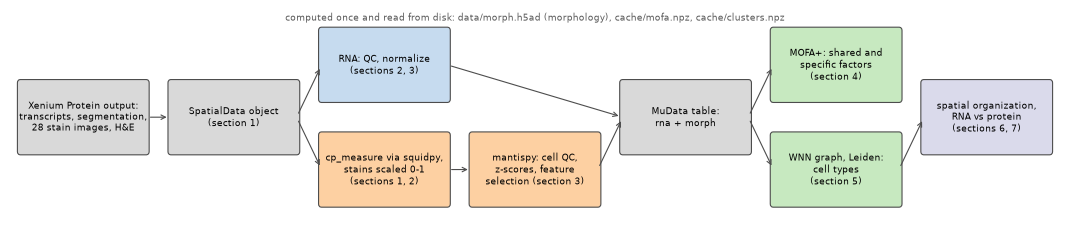

In [1]:
import logging
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="IProgress not found")  # progress bars without the notebook widget
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import muon as mu
import numpy as np
import pandas as pd
import scanpy as sc
import spatialdata as sd
import spatialdata_plot  # noqa: F401  (adds the .pl accessor)
from scipy.stats import spearmanr
from sklearn.neighbors import NearestNeighbors

import helpers

logging.getLogger("distributed").setLevel(logging.ERROR)  # squidpy's worker processes report their shutdown
logging.getLogger("ome_zarr").setLevel(logging.ERROR)  # notes about the OME-Zarr layout when reading zarr stores
sc.settings.verbosity = 0
plt.rcParams["figure.dpi"] = 80

DATA_DIR = Path("../data")  # about 22 GB of raw data, plus 8.5 GB of morphology features once computed
CACHE = Path("cache")  # the trained MOFA+ model and the clusterings
RETRAIN = False  # True: train MOFA+ again (needs an NVIDIA GPU) and recompute the clusterings


def cached(name, cells):
    # a cached result, and the position of each of `cells` (cell ids) in it
    result = np.load(CACHE / f"{name}.npz")
    position = pd.Index(result["cell_id"]).get_indexer(cells)
    assert (position >= 0).all(), f"{name}: cells missing from the cache, set RETRAIN = True"
    return result, position


_ = helpers.draw_pipeline()

**Before you run.** The environment is created with `uv sync` in the repository (see its README). It installs
development branches of spatialdata, spatialdata-io, spatialdata-plot, squidpy, cp_measure and mantispy that are not
released yet. Three results take a long time to compute, so they are computed once and then read from disk:

| result | file | computed by | first run | needs |
|---|---|---|---|---|
| morphology features | `data/morph.h5ad` (8.5 GB) | `helpers.morphology`, section 1 | about 2.5 hours on 64 CPU cores | disk for a temporary copy of the stain images |
| MOFA+ model | `cache/mofa.npz` (in the repository) | `helpers.train_mofa`, section 4 | about 15 minutes | an NVIDIA GPU |
| clusterings and WNN weights | `cache/clusters.npz` (in the repository) | section 5 | about 15 minutes | |

With these files present, the notebook ran in about 16 minutes on a node with 16 CPU cores, 192 GB of memory and a GPU.
`RETRAIN = True` recomputes the MOFA+ model and the clusterings. The cluster numbers quoted in the text, and the
annotation of section 5, refer to the clustering in `cache/`.

## 1. The tissue

*What does the section look like, and which regions did the pathologist mark?*

The data are downloaded once (only the files used here, about 22 GB of the 36 GB bundle). `helpers.load` assembles them
into a SpatialData object; the images are read lazily, so loading takes seconds.

In [2]:
helpers.download(DATA_DIR)
sdata = helpers.load(DATA_DIR)
sdata

/ictstr01/groups/ml01/workspace/tim.treis/spatialdata-multiomics-demo/.venv/lib/python3.13/site-packages/scanpy/readwrite.py:322: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  return AnnData(matrix, obs=obs_dict, var=var_dict)


/ictstr01/groups/ml01/workspace/tim.treis/spatialdata-multiomics-demo/.venv/lib/python3.13/site-packages/mudata/_core/mudata.py:988: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  self._update_attr("var", axis=1, join_common=join_common)


SpatialData object
├── Images
│     ├── 'he': DataTree[cyx] (3, 60680, 24096), (3, 30340, 12048), (3, 15170, 6024), (3, 7585, 3012), (3, 3793, 1506), (3, 1897, 753)
│     └── 'stains': DataTree[cyx] (28, 27328, 54002), (28, 13664, 27001), (28, 6832, 13500), (28, 3416, 6750), (28, 1708, 3375)
├── Labels
│     └── 'cell_labels': DataTree[yx] (27328, 54002), (13664, 27001), (6832, 13500), (3416, 6750), (1708, 3375)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (465534, 1) (2D shapes)
│     ├── 'nucleus_boundaries': GeoDataFrame shape: (471228, 2) (2D shapes)
│     └── 'pathology': GeoDataFrame shape: (9, 2) (2D shapes)
└── Tables
      └── 'table': MuData (465534, 405)
with coordinate systems:
    ▸ 'global', with elements:
        he (Images), stains (Images), cell_labels (Labels), cell_boundaries (Shapes), nucleus_boundaries (Shapes), pathology (Shapes)

A SpatialData object holds the parts of one experiment in a shared coordinate system, `global`, in pixels of the stain
images (0.2125 µm):

- **Images**: `stains`, the DAPI and the 27 protein stains as 28 channels, and `he`, the H&E. Each is a pyramid of
  resolutions (`scale0` is the full resolution, each further level half the size), read from disk only when needed.
- **Labels**: `cell_labels`, the segmentation, an image in which each pixel holds the number of the cell it belongs to.
- **Shapes**: the outlines of the cells and nuclei as polygons, and the 9 polygons of the pathology annotation.
- **Tables**: `table`, one row per cell, linked to `cell_labels` by the cell's number.

The H&E was stained on the same section after the Xenium run and registered to it, so the pathologist's annotation,
drawn on the H&E, can be laid over the cells.

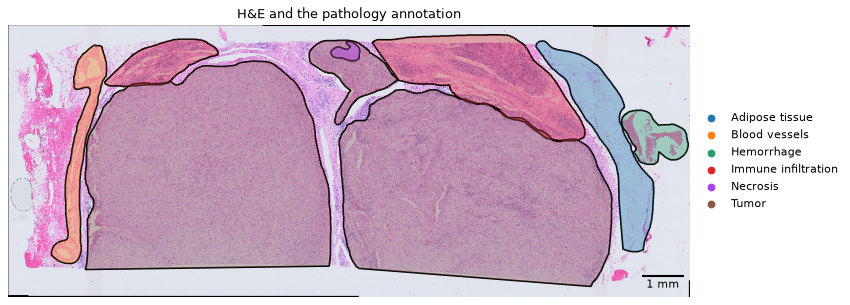

In [3]:
fig, ax = plt.subplots(figsize=(11, 10))
(
    sdata.pl.render_images("he")
    .pl.render_shapes("pathology", color="region", fill_alpha=0.35, outline_alpha=1, outline_width=1.5)
    .pl.show(coordinate_systems="global", ax=ax, title="H&E and the pathology annotation")
)
helpers.scale_bar(ax, 1000, "1 mm", units_per_pixel=helpers.PIXEL_SIZE)
ax.set_axis_off()

Most of the section is tumor, in two large nodules. The pathologist marked two bands of immune infiltration along the
upper edge, outside the nodules; we call them the immune infiltrate. The fibrous septum between the nodules is not
annotated. A band of fat runs along the right edge, and small areas of necrosis and hemorrhage lie at the margins. The
blood vessels and the hemorrhage are outside the area measured by the Xenium, so no cells fall in them.

The table is a MuData object: a container of AnnData objects, one per *modality*, that describe the same cells. Its own
`obs` (the cell id, area, transcript counts) and `obsm["spatial"]` (the cell centroids, in µm) belong to the cells and
are shared by all modalities; each modality has its own `X`, `var` and layers. spatialdata-io reads the Xenium output
with an `"rna"` and a `"prot"` modality, the latter holding 10x's mean intensity of each stain per cell. `helpers.load`
removes `"prot"`, because we measure the stains ourselves, with many more features than the mean. For now the table has
one modality, the RNA.

`helpers.pathology_region` gives each cell the region whose polygon contains its centroid. Where two regions overlap,
the later one in `helpers.REGION_ORDER` wins; cells in no polygon are `unannotated`.

In [4]:
mdata = sdata["table"]
mdata.obs["pathology"] = pd.Categorical(helpers.pathology_region(sdata))
stages = {"segmented": mdata.n_obs}  # the cells at each stage, summarized at the end of section 3
mdata

MuData object with n_obs × n_vars = 465534 × 405
  obs:	'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'pathology'
  uns:	'spatialdata_attrs'
  obsm:	'spatial'
  1 modality
    rna:	465534 × 405
      var:	'gene_ids', 'feature_types', 'genome'
      layers:	None

### The second modality, measured from the images

For each cell, cp_measure computes features of each of the 28 images within the cell's outline. Its features fall into
five groups:

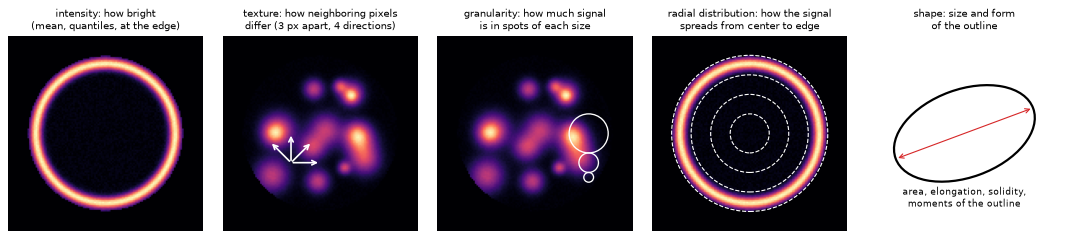

In [5]:
_ = helpers.draw_feature_groups()

| group | what it measures | example name | parameters in the name |
|---|---|---|---|
| Intensity | mean, median, quantiles and edge intensity of a stain in the cell | `Intensity_MeanIntensity__CD8A` | |
| Texture (Haralick) | how the intensities of pixels 3 pixels apart co-occur: contrast, entropy, homogeneity | `Contrast_3_00_256__PD-1` | distance 3, direction 00 to 03 (0, 45, 90, 135 degrees), 256 gray levels |
| Granularity | the fraction of the signal in bright spots of increasing size | `Granularity_4__Ki-67` | spot size |
| Radial distribution | how the signal spreads from the cell's center to its edge, in rings and as Zernike moments of its pattern | `RadialDistribution_ZernikeMagnitude_8_8__CD8A` | ring, or Zernike order |
| Shape | size and form of the outline: area, elongation, solidity, moments | `Area`, `InertiaTensorEigenvalues_1` | |

Before measuring, `helpers.morphology` scales each stain to 0-1 (`helpers.stain_ranges`). Its background (the median of
the tissue pixels outside any cell) becomes 0 and its brightest cells (the 99.99th percentile of the pixels inside
cells) become 1. Both are estimated on a 4-fold downsampled level of the image, and values outside the range are
clipped. Subtracting the background matters, because the camera adds about 99 counts to every pixel of a protein stain,
and a sparse stain such as GranzymeB barely rises above that outside its few positive cells. Without it, the positive
cells would be a sliver at the top of the range, and every ratio the features compute (how much of a stain lies at the
edge of the cell, for example) would measure the offset rather than the protein. The range also decides how finely
texture is resolved, since cp_measure divides it into 256 gray levels.

squidpy runs cp_measure on the SpatialData object, tile by tile and in parallel. On this section that takes about 2.5
hours on 64 CPU cores, so the result is saved in `data/morph.h5ad` and read from there afterwards.

In [6]:
raw = helpers.morphology(sdata, DATA_DIR)  # the raw features, one row per cell, indexed by cell_id
stages["with morphology features"] = raw.n_obs
print(f"{raw.n_obs} cells x {raw.n_vars} features, e.g.", ", ".join(raw.var_names[[0, 60, 700, 2000]]))

462905 cells x 4514 features, e.g. Area, NormalizedMoment_3_3, RadialDistribution_ZernikeMagnitude_8_8__CD8A, Location_MaxIntensity_X__PD-1


## 2. Quality control

*Which cells were measured well enough to analyze, in each modality?*

### RNA: transcripts per cell and cell size

A cell with few transcripts cannot be typed reliably, and a very small or very large "cell" is usually a segmentation
error (a fragment, or several cells merged). We keep cells with at least 20 transcripts and an area of 10 to 600 µm².

median transcripts per cell: 70


fewer than 20 transcripts    8.3%
area outside 10-600 µm²      1.0%
removed                      8.5%
dtype: str

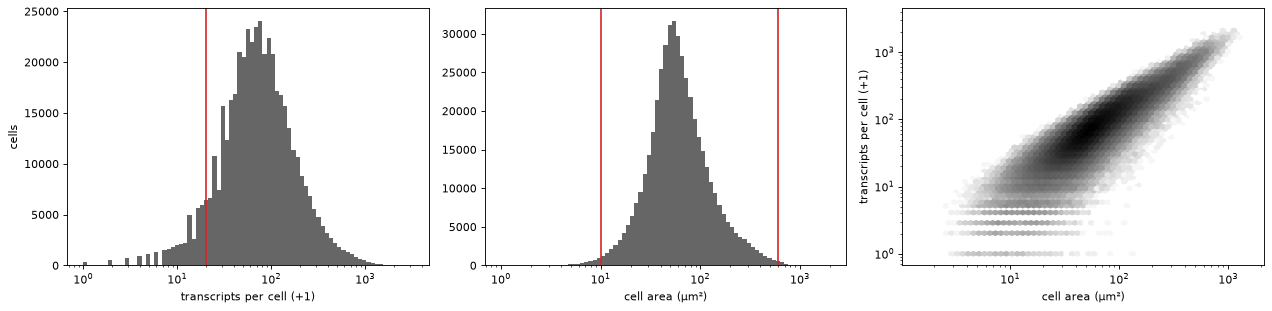

In [7]:
MIN_TRANSCRIPTS, MIN_AREA, MAX_AREA = 20, 10, 600
obs = mdata.obs
fails = pd.DataFrame({
    "fewer than 20 transcripts": obs["transcript_counts"] < MIN_TRANSCRIPTS,
    "area outside 10-600 µm²": ~obs["cell_area"].between(MIN_AREA, MAX_AREA),
})
fails["removed"] = fails.any(axis=1)

fig, axs = plt.subplots(1, 3, figsize=(16, 4))
axs[0].hist(obs["transcript_counts"] + 1, bins=np.logspace(0, 3.5, 80), color="0.4")
axs[0].axvline(MIN_TRANSCRIPTS, color="C3")
axs[0].set(xscale="log", xlabel="transcripts per cell (+1)", ylabel="cells")
axs[1].hist(obs["cell_area"], bins=np.logspace(0, 3.3, 80), color="0.4")
for x in (MIN_AREA, MAX_AREA):
    axs[1].axvline(x, color="C3")
axs[1].set(xscale="log", xlabel="cell area (µm²)")
axs[2].hexbin(obs["cell_area"], obs["transcript_counts"] + 1, xscale="log", yscale="log", gridsize=60, bins="log",
              cmap="Greys")
axs[2].set(xlabel="cell area (µm²)", ylabel="transcripts per cell (+1)")
plt.tight_layout()
print(f"median transcripts per cell: {obs['transcript_counts'].median():.0f}")
fails.mean().map("{:.1%}".format)

A median cell has 70 transcripts, from a panel of 405 genes, so most genes are not detected in most cells. 8.3% of the
cells have fewer than 20 transcripts and 1% an implausible area; 8.5% are removed in all. The number of transcripts
grows with the cell area (right), which the normalization in section 3 accounts for.

### Where are the low-quality cells?

Quality is rarely uniform across a section. A map shows whether the removed cells are scattered or concentrated in a
region (for example necrosis, or a fold of the tissue), which would bias what we can say about that region.

Adipose tissue         10.7%
Immune infiltration    11.8%
Necrosis               36.3%
Tumor                   6.8%
unannotated            14.4%
Name: removed by QC, dtype: str

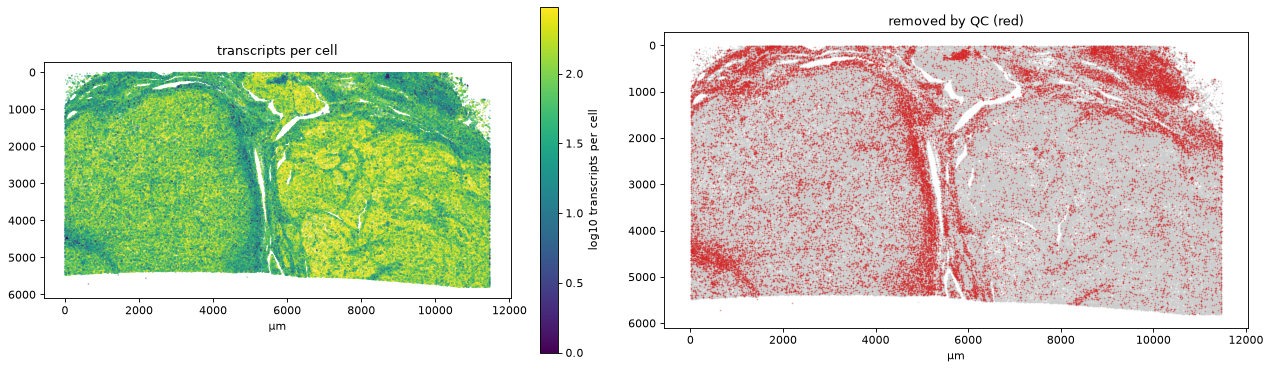

In [8]:
xy = mdata.obsm["spatial"]  # cell centroids, µm
fig, axs = plt.subplots(1, 2, figsize=(16, 7.5))
im = axs[0].scatter(xy[:, 0], xy[:, 1], c=np.log10(obs["transcript_counts"] + 1), s=0.05, cmap="viridis",
                    vmax=np.log10(300), rasterized=True)
fig.colorbar(im, ax=axs[0], shrink=0.6, label="log10 transcripts per cell")
axs[0].set_title("transcripts per cell")
removed = fails["removed"].to_numpy()
axs[1].scatter(xy[~removed, 0], xy[~removed, 1], s=0.05, color="0.8", rasterized=True)
axs[1].scatter(xy[removed, 0], xy[removed, 1], s=0.05, color="C3", rasterized=True)
axs[1].set_title("removed by QC (red)")
for ax in axs:
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.set_xlabel("µm")
plt.tight_layout()
fails.groupby(mdata.obs["pathology"].to_numpy())["removed"].mean().map("{:.1%}".format).rename("removed by QC")

The removed cells are not spread evenly. They concentrate in the fibrous septum between the tumor nodules and along the
upper edge, where cells are small and poor in transcripts. The unannotated tissue, mostly the septum, loses 14% of its
cells, the immune infiltrate 12%, the tumor 7% and the small necrotic areas a third (table). Comparisons between the
tumor and the immune infiltrate are therefore made on somewhat fewer, and larger, cells of the infiltrate.

### Morphology: how bright is each stain?

The mean intensity of a stain over a cell is the simplest of its measurements. After the scaling, the values of
different stains are comparable in range, and how they are spread tells whether a stain separates positive from negative
cells.

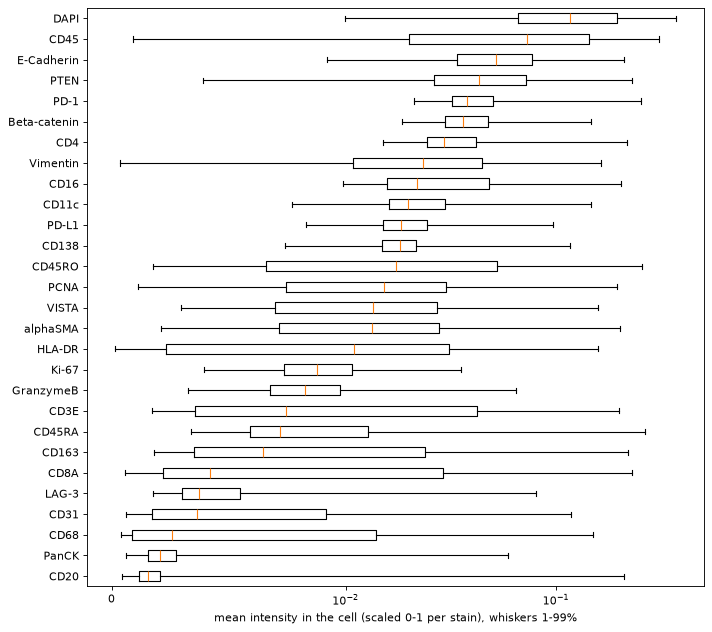

In [9]:
STAINS = list(helpers.STAINS)
mean_intensity = pd.DataFrame(raw[:, [f"Intensity_MeanIntensity__{s}" for s in STAINS]].X, index=raw.obs_names,
                              columns=STAINS)
order = mean_intensity.median().sort_values().index
fig, ax = plt.subplots(figsize=(9, 8))
ax.boxplot([mean_intensity[s] for s in order], orientation="horizontal", showfliers=False, whis=(1, 99))
ax.set_xscale("symlog", linthresh=0.01)  # linear near 0, where a cell at its stain's background lies
ax.set(yticks=range(1, len(order) + 1), yticklabels=order,
       xlabel="mean intensity in the cell (scaled 0-1 per stain), whiskers 1-99%")
plt.tight_layout()

Most stains have their median cell near 0, their background, and a long tail of bright cells: the shape expected of a
marker that only some cells carry. The stains of abundant cell types spread widest (CD45, Vimentin, CD45RO, CD3E, CD8A,
CD163, CD68), those of rare populations least (CD20, LAG-3, Ki-67). PanCK also spreads little, as ccRCC cells often
carry it only weakly or in patches. DAPI, in every nucleus, is the brightest. E-cadherin is an exception: its median is
high, although ccRCC cells, which derive from the proximal tubule, are usually E-cadherin negative. Much of its signal
is background, and its brightest cells turn out to be neutrophils (section 5).

### The stains themselves

Numbers per cell are only as good as the images behind them. A crop of a few stains shows whether the signal is
membranous or cytoplasmic as expected, and whether it is specific.

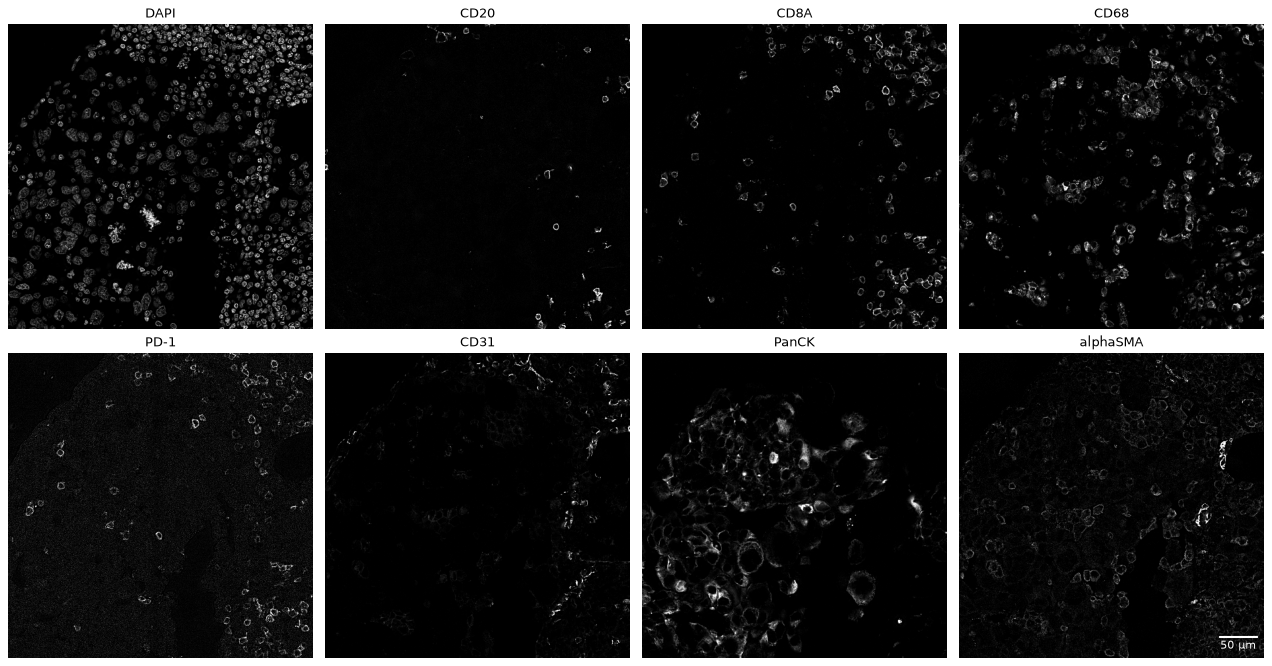

In [10]:
# a 400 µm window at the center of the tissue
cx, cy = np.median(xy, axis=0) / helpers.PIXEL_SIZE
half = 200 / helpers.PIXEL_SIZE
crop = sdata.query.bounding_box(axes=("x", "y"), min_coordinate=[cx - half, cy - half],
                                max_coordinate=[cx + half, cy + half], target_coordinate_system="global")
channels = ["DAPI", "CD20", "CD8A", "CD68", "PD-1", "CD31", "PanCK", "alphaSMA"]  # 8 of the 27 stains
fig, axs = plt.subplots(2, 4, figsize=(16, 8.5))
for ax, channel in zip(axs.flat, channels, strict=True):
    pixels = crop["stains"]["scale0"]["image"].sel(c=channel).data[::4, ::4].compute()
    norm = plt.Normalize(*np.percentile(pixels, [50, 99.9]))  # black at the background, white at the brightest cells
    crop.pl.render_images("stains", channel=channel, cmap="gray", norm=norm, colorbar=False).pl.show(
        coordinate_systems="global", ax=ax, title=channel)
    ax.set_axis_off()
helpers.scale_bar(axs.flat[-1], 50, "50 µm", units_per_pixel=helpers.PIXEL_SIZE, color="w")
plt.tight_layout()

The stains look as expected. DAPI marks every nucleus, CD8A outlines a scattered population of small cells and PD-1
rings a subset of them, CD68 marks the larger macrophages, PanCK a nest of epithelial tumor cells and CD31 thin vessel
walls. CD20 has little signal here, because the window lies inside the tumor, where B cells are rare. alphaSMA shows a
faint outline of many cells, likely background, and a few bright cells.

We apply the QC filter to the table, and keep the cells that have morphology features (cp_measure skips a few very small
cells).

In [11]:
mu.pp.filter_obs(mdata, "transcript_counts", lambda x: x >= MIN_TRANSCRIPTS)
mu.pp.filter_obs(mdata, "cell_area", lambda x: (x >= MIN_AREA) & (x <= MAX_AREA))
mu.pp.filter_obs(mdata, "cell_id", lambda x: x.astype(str).isin(raw.obs_names))
stages["after the RNA QC"] = mdata.n_obs
print(mdata.n_obs, "cells kept")
mdata.obs["pathology"].value_counts()

425600 cells kept


pathology
Tumor                  309888
Immune infiltration     84149
unannotated             30362
Necrosis                  827
Adipose tissue            374
Name: count, dtype: int64

## 3. Preparing each modality

*How do we make cells comparable within each modality?*

The two modalities are measured differently, so each is prepared on its own before they are modeled together.

**RNA.** A larger cell, or one cut through its middle, yields more transcripts of every gene. Dividing by the total per
cell (and scaling to the median total) removes this, and a log transform tempers the few very high counts.

**Morphology.** The morphology features are not normalized per cell: mean intensities do not grow with size, and the
size itself is a feature. The plots check both.

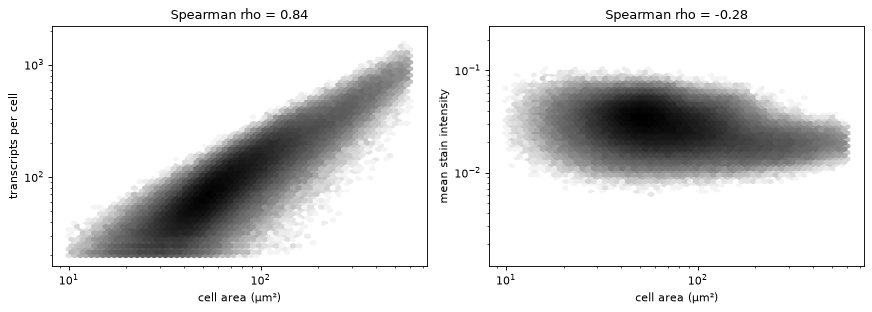

In [12]:
rna = mdata.mod["rna"]
area = mdata.obs["cell_area"].to_numpy()
total_rna = np.asarray(rna.X.sum(axis=1)).ravel()
stain_mean = mean_intensity.loc[mdata.obs_names].drop(columns="DAPI").mean(axis=1).to_numpy()
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, values, label in [(axs[0], total_rna, "transcripts per cell"), (axs[1], stain_mean, "mean stain intensity")]:
    ax.hexbin(area, values, xscale="log", yscale="log", gridsize=60, bins="log", cmap="Greys")
    ax.set(xlabel="cell area (µm²)", ylabel=label, title=f"Spearman rho = {spearmanr(area, values).statistic:.2f}")
plt.tight_layout()
helpers.normalize_rna(rna)  # normalize to the median total, log1p; the counts are kept in rna.layers["counts"]

The transcripts grow almost in proportion to the area of the cell (left, rho 0.84), which the normalization removes. The
mean intensity of the stains hardly depends on it (right, rho -0.28, slightly lower in the large tumor cells, which
carry few of the stains).

### Morphology: a stain to leave out

Every stain was scaled from its background, so a cell with no pixel above the background of a stain is uniformly 0 in
it, and the texture of a uniform image is undefined. The table gives, per stain, the fraction of cells where this
happens.

In [13]:
texture = raw[mdata.obs_names][:, raw.var_names.str.startswith("Contrast_")]  # one texture feature, 4 angles per stain
undefined = pd.DataFrame(np.isnan(texture.X), columns=texture.var_names.str.split("__").str[-1])  # NaN: undefined
undefined = undefined.T.groupby(level=0).any().T  # a cell without signal in a stain: undefined at any angle
undefined.mean().sort_values(ascending=False).head(8).map("{:.1%}".format).rename("cells without signal").to_frame().T

,HLA-DR,CD68,Vimentin,CD20,CD45RO,CD8A,CD45,PanCK
cells without signal,7.5%,1.0%,0.6%,0.6%,0.5%,0.4%,0.2%,0.2%


HLA-DR stands out: its texture is undefined in 7.5% of the cells, seven times more often than for any other stain. We
leave HLA-DR out of the morphology (`helpers.EXCLUDED_STAINS`) instead of removing those cells, which are by definition
all HLA-DR negative. HLA-DR stays in the RNA, as *HLA-DRA*.

### Morphology: the mantispy workflow

We prepare the morphology features with [mantispy](https://mantispy.readthedocs.io), following the standard steps of
image-based profiling. It removes cells at the edge of the scanned area and cells with an undefined feature, z-scores
each feature, and drops features that are constant or correlated above 0.9 with another. We change two of mantispy's
defaults, which are designed for screens, so that sparse stains such as PD-L1 and CD20 keep their features.

<details>
<summary><b>The workflow in detail</b></summary>

mantispy is built for image-based screens such as Cell Painting, where cells come from many plates and wells and
normalization is done per plate. It reads the features into an AnnData whose `var` has one row per feature, with its
group, stain (`channel`) and parameters (`angle`, `gray_levels`, `radial_bin`), and identifies each cell by plate, well,
image and object number. Our section is one plate, one well and one image, so every per-plate step runs over all cells
of the section. `helpers.morphology_profiles` translates squidpy's feature names into CellProfiler's
(`Contrast_3_00_256__PD-1` becomes `Cells_Texture_Contrast_PD-1_3_00_256`). It also leaves out the HLA-DR features and
the spatial moments, which depend on where the cell lies in the image. mantispy drops the location features itself.

The steps, as `helpers.preprocess_morphology` runs them:

1. **Cell QC** (`calculate_qc_metrics`, `filter_cells`): a cell with an undefined feature is removed, and so is a cell
   whose center lies within 20 µm of the edge of the scanned area, where the stains are cut off. mantispy also flags
   cells with an unusual area. In a screen these are segmentation errors. In a tissue they are large or small cell
   types, so we keep them and look at the flag per cell type in section 5.
2. **Feature QC** (`filter_features`): features with a variance below 1e-8 are removed.
3. **Normalization** (`normalize`): each feature is z-scored over all cells.
4. **Feature selection** (`feature_select`, with the steps mantispy uses for single cells): a feature is removed if its
   scale was 0 before normalization (degenerate), its variance is near 0, a value is missing, its largest absolute value
   exceeds 500, or it correlates above 0.9 (Pearson) with a feature that is kept. The correlation step removes most
   features here, because many features of one stain measure nearly the same thing.

The two settings that differ from the defaults are the normalization (z-scores instead of median/MAD) and the handling
of undefined values (removing the cells instead of the features). The next cells show why.
</details>

In [14]:
import mantispy as mt

centroids = pd.DataFrame(mdata.obsm["spatial"], index=mdata.obs_names)  # µm, for the border check
profiles = helpers.morphology_profiles(raw[mdata.obs_names], centroids)
IMAGE_SHAPE = sdata["stains"]["scale0"]["image"].shape[1:]  # (height, width) of the stains, in pixels
print(f"{profiles.n_vars} of the {raw.n_vars} raw features, without the spatial moments and HLA-DR")
profiles.var["feature_group"].value_counts().rename("features").to_frame().T

4201 of the 4514 raw features, without the spatial moments and HLA-DR


feature_group,RadialDistribution,Texture,Intensity,Granularity,AreaShape,Location
features,1944,1404,403,393,57,0


mantispy's default normalization, the median and the median absolute deviation (MAD), puts each feature on the scale of
a reference population. Most single cells are negative for a sparse stain such as PD-L1 or CD20, so the MAD of many of
its features is 0, and the selection discards them as degenerate. The cell below runs the workflow with both
normalizations on 50,000 random cells.

In [15]:
sample = profiles[np.sort(np.random.default_rng(0).choice(profiles.n_obs, 50_000, replace=False))]
rows = {}
for method in ["mad_robustize", "standardize"]:
    trial = helpers.preprocess_morphology(sample, IMAGE_SHAPE, method=method)
    rows[method] = {"features kept": trial.n_vars,
                    "removed as degenerate": trial.uns["feature_select"]["drop_degenerate"],
                    **{f"{stain} features": int((trial.var["channel"] == stain).sum())
                       for stain in ["PD-L1", "CD20", "GranzymeB"]}}
pd.DataFrame(rows).T

/ictstr01/groups/ml01/workspace/tim.treis/spatialdata-multiomics-demo/notebooks/helpers.py:339: UserWarning: 534 of 4155 features have no spread in at least one group of 'Metadata_Plate'. Adding epsilon=1e-18 to their scale multiplies them by up to 1e18, so they dominate every distance downstream. They are flagged in var['degenerate_scale'], and pp.feature_select drops them by default; to drop them now, adata = adata[:, ~adata.var['degenerate_scale']].copy(). A variance or outlier cut does not catch a feature that varies across a plate but is constant among its control wells; the flag does.
  mt.pp.normalize(a, method=method, by="Metadata_Plate", reference=None)  # over all cells of the one plate


/ictstr01/groups/ml01/workspace/tim.treis/spatialdata-multiomics-demo/notebooks/helpers.py:339: UserWarning: 27 of 4155 features have no spread in at least one group of 'Metadata_Plate'. Their scale is clamped to 1, which sets them to 0. They are flagged in var['degenerate_scale'], and pp.feature_select drops them by default; to drop them now, adata = adata[:, ~adata.var['degenerate_scale']].copy(). A variance or outlier cut does not catch a feature that varies across a plate but is constant among its control wells; the flag does.
  mt.pp.normalize(a, method=method, by="Metadata_Plate", reference=None)  # over all cells of the one plate


,features kept,removed as degenerate,PD-L1 features,CD20 features,GranzymeB features
mad_robustize,2250,534,97,53,87
standardize,2767,27,108,105,109


With the median/MAD, the sparse stains, which mark the rare cell states we are after, keep about half as many features
as with z-scores, so we use z-scores. And because a single cell with an undefined value would make the selection drop
that feature for all cells, we remove such cells instead, which keeps the texture features.

The cell below runs the workflow with these settings on all cells.

In [16]:
morph = helpers.preprocess_morphology(profiles, IMAGE_SHAPE)
print(f"{profiles.n_obs - morph.n_obs} cells removed by the QC (at the image border or with an undefined feature); "
      f"{morph.n_vars} of {profiles.n_vars} features kept")
print("features removed by each selection step:", morph.uns["feature_select"])
# the mean intensity of each stain, kept to read the stains as proteins in sections 5 to 7
morph.obsm["mean_intensity"] = mean_intensity.loc[morph.obs_names].drop(columns=list(helpers.EXCLUDED_STAINS))
mu.pp.filter_obs(mdata, "cell_id", lambda x: x.astype(str).isin(morph.obs_names))
mdata.mod["morph"] = morph[mdata.obs_names].copy()
mdata.update()
rna, morph = mdata.mod["rna"], mdata.mod["morph"]  # the filter may have replaced the modality objects
stages["after the morphology QC"] = mdata.n_obs
display(morph.var["feature_group"].value_counts().rename("selected features").to_frame().T)
mdata

/ictstr01/groups/ml01/workspace/tim.treis/spatialdata-multiomics-demo/notebooks/helpers.py:339: UserWarning: 27 of 4193 features have no spread in at least one group of 'Metadata_Plate'. Their scale is clamped to 1, which sets them to 0. They are flagged in var['degenerate_scale'], and pp.feature_select drops them by default; to drop them now, adata = adata[:, ~adata.var['degenerate_scale']].copy(). A variance or outlier cut does not catch a feature that varies across a plate but is constant among its control wells; the flag does.
  mt.pp.normalize(a, method=method, by="Metadata_Plate", reference=None)  # over all cells of the one plate


16802 cells removed by the QC (at the image border or with an undefined feature); 2794 of 4201 features kept
features removed by each selection step: {'drop_degenerate': 27, 'variance_threshold': 0, 'correlation_threshold': 1366, 'drop_na_columns': 0, 'blocklist': 0, 'drop_outliers': 8}


feature_group,RadialDistribution,Texture,Granularity,Intensity,AreaShape
selected features,1761,418,362,217,36


MuData object with n_obs × n_vars = 408798 × 3199
  obs:	'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'pathology'
  uns:	'spatialdata_attrs'
  obsm:	'spatial'
  2 modalities
    rna:	408798 × 405
      var:	'gene_ids', 'feature_types', 'genome'
      uns:	'log1p'
      layers:	None, 'counts'
    morph:	408798 × 2794
      obs:	'Metadata_Plate', 'Metadata_Well', 'Metadata_ImageID', 'Metadata_ObjectType', 'Metadata_ObjectNumber', 'Metadata_Row', 'Metadata_Col', 'Metadata_Center_X', 'Metadata_Center_Y', 'qc_n_nan_features', 'qc_nan_fraction', 'qc_is_border', 'qc_area_outlier', 'qc_pass'
      var:	'object', 'feature_group', 'feature', 'channel', 'scale', 'angle', 'gray_levels', 'radial_bin', 'params', 'is_feature', 'feature_kind', 'qc_n_nan', 'qc_v

The table now has both modalities, `rna` and `morph`, for the same cells. Radial distribution features are about two
thirds of the selected morphology features, so they carry the most weight in the morphology's principal components
below. The number of cells at each stage is shown below.

In [17]:
pd.Series(stages, name="cells").to_frame()

,cells
segmented,465534
with morphology features,462905
after the RNA QC,425600
after the morphology QC,408798


### Do the two modalities describe the cells in the same way?

After preprocessing, each modality gives its own representation of the cells, here the first 20 principal components of
each. If RNA and morphology see the same biology, cells that are similar in one should be similar in the other. We look
in two ways: at the two representations side by side, colored by the same cell properties, and at how many of each
cell's 20 nearest neighbors are the same in both.

The pictures are UMAPs of 50,000 random cells. A UMAP is a two-dimensional layout of the neighbor graph. It distorts
distances and serves only for orientation. The neighbor overlap is computed in the 20 dimensions, not in the UMAP.

shared nearest neighbors (of 20): median 0%; expected by chance 0.04%


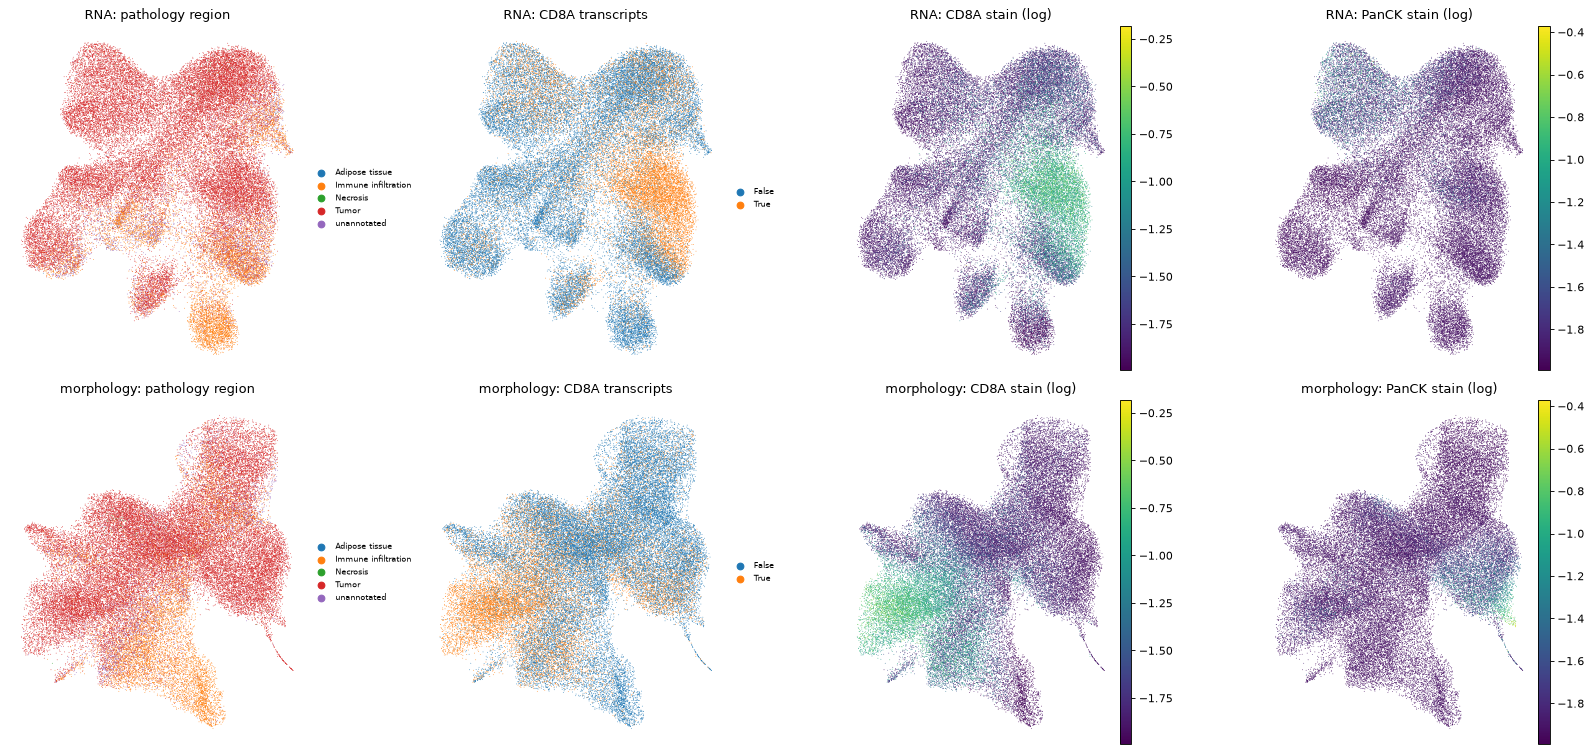

In [18]:
from sklearn.decomposition import PCA

sc.tl.pca(rna, n_comps=20, random_state=0)
# the morphology is a dense matrix of z-scores; scanpy's PCA would give the same components
morph.obsm["X_pca"] = PCA(n_components=20, svd_solver="randomized", random_state=0).fit_transform(morph.X)
latent = {"RNA": rna.obsm["X_pca"], "morphology": morph.obsm["X_pca"]}

cells = np.sort(np.random.default_rng(0).choice(mdata.n_obs, 50_000, replace=False))
show = {"pathology region": mdata.obs["pathology"].astype(str).to_numpy()[cells],
        "CD8A transcripts": sc.get.obs_df(rna[cells], keys=["CD8A"], layer="counts")["CD8A"].to_numpy() > 0,
        "CD8A stain (log)": np.log10(morph.obsm["mean_intensity"]["CD8A"].to_numpy()[cells] + 0.01),
        "PanCK stain (log)": np.log10(morph.obsm["mean_intensity"]["PanCK"].to_numpy()[cells] + 0.01)}
views = {}
for name, rep in latent.items():
    view = ad.AnnData(obs=pd.DataFrame(show, index=mdata.obs_names[cells]).astype(
        {"pathology region": "category", "CD8A transcripts": "category"}), obsm={"X": rep[cells]})
    sc.pp.neighbors(view, use_rep="X", n_neighbors=20, random_state=0)
    sc.tl.umap(view, random_state=0)
    views[name] = view
fig, axs = plt.subplots(2, len(show), figsize=(5 * len(show), 9.5))
for row, (name, view) in zip(axs, views.items(), strict=True):
    for ax, key in zip(row, show, strict=True):
        sc.pl.umap(view, color=key, ax=ax, show=False, size=2, frameon=False, title=f"{name}: {key}",
                   cmap="viridis", legend_fontsize=7)
plt.tight_layout()

nearest = {name: NearestNeighbors(n_neighbors=21).fit(rep[cells]).kneighbors(return_distance=False)[:, 1:]
           for name, rep in latent.items()}  # each cell's 20 nearest neighbors, without itself
shared = np.array([len(np.intersect1d(a, b)) for a, b in zip(nearest["RNA"], nearest["morphology"])]) / 20
print(f"shared nearest neighbors (of 20): median {np.median(shared):.0%}; "
      f"expected by chance {20 / len(cells):.2%}")

Both modalities find the same large groups. The CD8 T cells, with *CD8A* transcripts and bright CD8A stain, form one
region of each UMAP, and the PanCK-bright tumor cells form another. But the modalities disagree on which cells are
closest to each other. Of its 20 nearest neighbors in the RNA, the median cell shares none with its 20 nearest neighbors
in the morphology. Within a cell type, the two modalities order the cells differently. Part of this is noise, above all
the sampling of a few transcripts per cell, and part may be biology that only one modality sees. A joint model helps
tell the two apart, since variation that both modalities share is more likely to be real.

## 4. A joint model of RNA and morphology

*What structure is shared by the two modalities, and what is specific to one of them?*

**MOFA+** (Multi-Omics Factor Analysis) describes each modality as the product of two matrices: a score of every cell on
each of 20 *factors*, shared by the modalities, and a weight of every feature on each factor, per modality. A factor is
an axis of variation along which cells differ; its weights say which genes or image features change along it, and its
sign is arbitrary. For each factor and modality, MOFA+ reports the fraction of the modality's variance that the factor
explains, which shows whether a factor is shared by RNA and morphology or specific to one of them.

The inputs are the log-normalized RNA (all 405 genes) and the z-scored morphology features. Each modality is scaled to
the same total variance, so the 2,794 morphology features do not outweigh the 405 genes by their number. MOFA+ was
trained on all cells on a GPU (about 15 minutes). The notebook reads the trained model from `cache/mofa.npz`.

total variance explained (%): {'RNA': 18.899999618530273, 'morphology': 29.600000381469727}


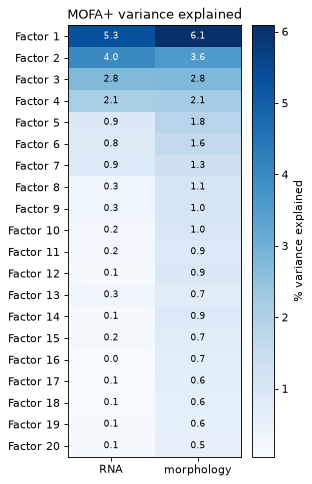

In [19]:
if RETRAIN or not (CACHE / "mofa.npz").exists():  # without a GPU, train_mofa fails
    rna.obs["cell_id"] = mdata.obs["cell_id"].to_numpy()  # train_mofa saves the factors keyed by cell_id
    helpers.train_mofa({"rna": rna, "morph": morph}, CACHE / "mofa.npz")

mofa, position = cached("mofa", mdata.obs_names)
assert list(mofa["features_morph"]) == list(morph.var_names), "the cached model has other features, set RETRAIN = True"
mdata.obsm["X_mofa"] = mofa["factors"][position].astype(np.float32)
r2 = pd.DataFrame({"RNA": mofa["r2_rna"], "morphology": mofa["r2_morph"]},
                  index=[f"Factor {i + 1}" for i in range(len(mofa["r2_rna"]))])
fig, ax = plt.subplots(figsize=(3.5, 7))
im = ax.imshow(r2.to_numpy(), cmap="Blues", aspect="auto")
ax.set(xticks=[0, 1], xticklabels=r2.columns, yticks=range(len(r2)), yticklabels=r2.index)
for (i, j), v in np.ndenumerate(r2.to_numpy()):
    ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8, color="w" if v > r2.to_numpy().max() / 2 else "k")
fig.colorbar(im, ax=ax, label="% variance explained")
ax.set_title("MOFA+ variance explained")
print("total variance explained (%):", r2.sum().round(1).to_dict())

The first four factors are shared: each explains a similar share of both modalities (2 to 6%). From factor 5 on, the
factors mostly explain variation in the images that the transcripts do not capture. In total MOFA+ explains 19% of the
variance of the RNA and 30% of the morphology. Much of the RNA variance is the sampling noise of a few transcripts per
cell, which no factor can explain.

### What do the main factors capture?

The features with the largest weights at each end of a factor, per modality, name the factor.

In [20]:
mofa_weights = {"RNA": pd.DataFrame(mofa["weights_rna"], index=mofa["features_rna"], columns=r2.index),
                "morphology": pd.DataFrame(mofa["weights_morph"], index=helpers.feature_labels(morph.var),
                                           columns=r2.index)}


def top_features(factor, n=4):
    out = {}
    for view, w in mofa_weights.items():
        out[f"{view} +"] = ", ".join(w[factor].nlargest(n).index)
        out[f"{view} -"] = ", ".join(w[factor].nsmallest(n).index)
    return out


main_factors = r2.sum(axis=1).nlargest(8).index
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame({f: top_features(f) for f in main_factors}).T.assign(
        **{"% RNA": r2["RNA"], "% morphology": r2["morphology"]}).loc[main_factors].round(1))

,RNA +,RNA -,morphology +,morphology -,% RNA,% morphology
Factor 1,"PTPRC, CD8A, CD3E, HLA-DRA","VIM, VCAN, ACTA2, CAVIN1","CD45 intensity: median intensity, CD45 intensity: max intensity edge, CD45RO texture: difference entropy, CD45 radial distribution: Zernike magnitude","CD45 texture: info meas 1, CD45 texture: inverse difference moment, CD3E texture: inverse difference moment, CD8A texture: inverse difference moment",5.3,6.1
Factor 2,"FCGR3A, HLA-DRA, FCGR3B, CD68","MS4A1, CXCR4, PTPRC, CD79A","CD16 texture: entropy, CD45RA texture: info meas 1, CD68 texture: entropy, CD163 texture: entropy","CD16 granularity: granularity 1.0, CD45RA intensity: max intensity, CD45RA texture: entropy, CD45RA intensity: median intensity",4.0,3.6
Factor 3,"HLA-DRA, FCGR3A, CD68, HLA-DRB1","CD8A, VIM, CCL5, ACTA2","CD68 texture: entropy, LAG-3 texture: info meas 1, LAG-3 texture: inverse difference moment, Vimentin texture: info meas 1","PD-1 radial distribution: Zernike magnitude, PD-1 radial distribution: Zernike magnitude, CD8A intensity: integrated intensity, PD-1 intensity: median intensity",2.8,2.8
Factor 4,"CXCL6, MET, VIM, KRT8","PECAM1, CD93, ACTA2, VWF","PD-1 intensity: integrated intensity, shape: inertia tensor eigenvalues, PanCK texture: difference entropy, CD31 texture: inverse difference moment","CD31 texture: difference entropy, CD31 texture: info meas 2, CD31 texture: info meas 2, CD31 texture: info meas 2",2.1,2.1
Factor 5,"MS4A1, HLA-DRA, VIM, BANK1","MZB1, TENT5C, SLAMF7, PECAM1","CD20 intensity: integrated intensity, E-Cadherin texture: difference entropy, CD20 radial distribution: Zernike magnitude, CD20 texture: contrast","E-Cadherin texture: inverse difference moment, E-Cadherin texture: inverse difference moment, E-Cadherin texture: inverse difference moment, E-Cadherin texture: inverse difference moment",0.9,1.8
Factor 6,"MZB1, PECAM1, TENT5C, SLAMF7","CD8A, CCL5, HLA-DRA, NKG7","CD138 texture: sum entropy, CD138 intensity: integrated intensity edge, CD138 intensity: integrated intensity, CD138 intensity: max intensity","CD138 texture: difference variance, CD138 texture: difference variance, CD138 texture: difference variance, CD138 texture: difference variance",0.8,1.6
Factor 7,"IL7R, PTPRC, CD3E, TRAC","MS4A1, HLA-DRA, PECAM1, CD79A","CD4 texture: sum variance, CD4 intensity: integrated intensity edge, CD4 texture: sum variance, CD4 intensity: median intensity","CD20 intensity: integrated intensity, CD4 granularity: granularity 1.0, CD4 texture: difference variance, CD20 intensity: median intensity",0.9,1.3
Factor 8,"FCGR3A, HLA-DRA, FCGR3B, MKI67","PECAM1, VWF, VIM, CD93","Ki-67 texture: sum average, Ki-67 radial distribution: Zernike magnitude, Ki-67 radial distribution: Zernike magnitude, Ki-67 radial distribution: Zernike magnitude","Ki-67 texture: info meas 1, Ki-67 texture: info meas 1, CD11c intensity: integrated intensity, Beta-catenin texture: difference entropy",0.3,1.1


In both modalities the top features point to the same cell types, so the main factors are cell type axes:

- **Factor 1** separates immune cells (*PTPRC*, *CD8A*, *CD3E*; CD45 intensity) from stroma and tumor (*VIM*, *VCAN*,
  *ACTA2*).
- **Factor 2** separates myeloid cells (*FCGR3A*, *CD68*; CD16 and CD68 texture) from the lymphocytes of the infiltrate
  (*MS4A1*, *CXCR4*, *IL7R*; CD45RA).
- **Factor 3** separates myeloid and B cells from CD8 T cells (*CD8A*, *CCL5*; PD-1 radial distribution).
- **Factor 4** separates tumor (*CXCL6*, *MET*, *KRT8*; cell size) from blood vessels (*PECAM1*, *VWF*; CD31 texture).
- **Factor 5** separates B cells (*MS4A1*, *BANK1*; CD20 intensity) from plasma cells (*MZB1*, *SLAMF7*).

The later, mostly morphological factors pick out plasma cells (factor 6: *MZB1*, *SDC1*; CD138), CD4 T cells (factor 7)
and proliferation (factor 8: *MKI67*; Ki-67 texture).

### Where are the factors active in the tissue?

Each cell is colored by its score on a factor: red at the end named first in the title, blue at the other.

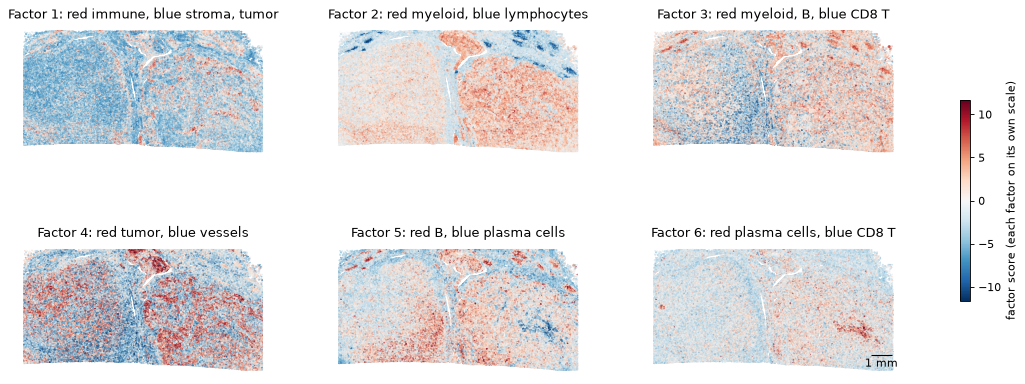

In [21]:
POLES = {"Factor 1": ("immune", "stroma, tumor"), "Factor 2": ("myeloid", "lymphocytes"),
         "Factor 3": ("myeloid, B", "CD8 T"), "Factor 4": ("tumor", "vessels"), "Factor 5": ("B", "plasma cells"),
         "Factor 6": ("plasma cells", "CD8 T")}
xy = mdata.obsm["spatial"]  # the centroids of the cells kept by the QC, µm
fig, axs = plt.subplots(2, 3, figsize=(18, 6.5))
for ax, factor in zip(axs.flat, main_factors[:6], strict=True):
    values = mdata.obsm["X_mofa"][:, r2.index.get_loc(factor)]
    lo, hi = np.percentile(values, [1, 99])
    im = ax.scatter(xy[:, 0], xy[:, 1], c=values, s=0.03, cmap="RdBu_r", vmin=-max(-lo, hi), vmax=max(-lo, hi),
                    rasterized=True)
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.set_axis_off()
    ax.set_title(f"{factor}: red {POLES[factor][0]}, blue {POLES[factor][1]}")
helpers.scale_bar(axs.flat[-1], 1000, "1 mm")
fig.colorbar(im, ax=axs, shrink=0.5, label="factor score (each factor on its own scale)")

The maps show how the section is organized. The round patches along the upper edge, in the immune infiltrate, are
lymphoid aggregates rich in B cells (blue in factor 2, red in factors 3 and 5). Factor 4 outlines the tumor nodules
(red) against the vessel-rich septum between them (blue). The maps also suggest that the two nodules differ. The right
one is richer in myeloid cells (factor 2). The left one has more tumor and stroma relative to immune cells (factor 1),
and its immune cells lean to CD8 T cells over myeloid cells (factor 3). A pocket of plasma cells sits in the lower part
of the right nodule (factor 6).

## 5. Cell types

*Which cell types are there, and what does the morphology add to the RNA in defining them?*

We cluster the cells twice: on the RNA alone, and on the RNA and the morphology together. Both start from a neighbor
graph, which links each cell to the 20 cells most similar to it, in the 20 principal components of section 3.

For the joint graph we do not decide how much each modality counts. **Weighted nearest neighbors** (WNN, the method from
Seurat, here as implemented in muon) learns this for every cell, from how well each modality's neighbors predict the
cell's profile. The joint graph combines the two graphs by these weights. WNN works on the principal components of each
modality. We use MOFA+ to interpret the shared and specific variation, and WNN to build the graph we cluster.

**Leiden** then splits a graph into communities of cells more connected to each other than to the rest. Its `resolution`
sets how fine the split is, and the result depends on it and on the random seed, which is why the clusterings are read
from `cache/clusters.npz`. Comparing the two clusterings shows what the morphology adds.

In [22]:
path = CACHE / "clusters.npz"
if RETRAIN or not path.exists():
    helpers.patch_muon_wnn()  # muon 0.2.0 returns NaN for cells whose neighbors have identical profiles
    sc.pp.neighbors(rna, use_rep="X_pca", n_neighbors=20, random_state=0)
    sc.pp.neighbors(morph, use_rep="X_pca", n_neighbors=20, random_state=0)
    mu.pp.neighbors(mdata, n_neighbors=20, key_added="wnn")  # stores each cell's weights as "<modality>:mod_weight"
    sc.tl.leiden(rna, resolution=1.0, flavor="igraph", n_iterations=2, random_state=0, key_added="leiden")
    sc.tl.leiden(mdata, neighbors_key="wnn", resolution=1.0, flavor="igraph", n_iterations=2, random_state=0,
                 key_added="leiden_joint")
    np.savez_compressed(path, cell_id=mdata.obs_names.to_numpy().astype(str),
                        leiden_rna=rna.obs["leiden"].astype(int).to_numpy(),
                        leiden_joint=mdata.obs["leiden_joint"].astype(int).to_numpy(),
                        rna_weight=mdata.obs["rna:mod_weight"].to_numpy().astype(np.float32))
clusters, position = cached("clusters", mdata.obs_names)
for name in ["rna", "joint"]:
    labels = clusters[f"leiden_{name}"][position]
    mdata.obs[f"leiden_{name}"] = pd.Categorical(labels.astype(str), categories=[str(c) for c in np.unique(labels)])
mdata.obs["rna_weight"] = clusters["rna_weight"][position]
mdata.obs["morph_weight"] = 1 - mdata.obs["rna_weight"]
print(f"mean weight of the RNA across cells: {mdata.obs['rna_weight'].mean():.2f}")
mdata.obs[["leiden_rna", "leiden_joint"]].nunique().to_frame("clusters").T

mean weight of the RNA across cells: 0.48


,leiden_rna,leiden_joint
clusters,14,17


agreement of the two clusterings (adjusted Rand index): 0.54


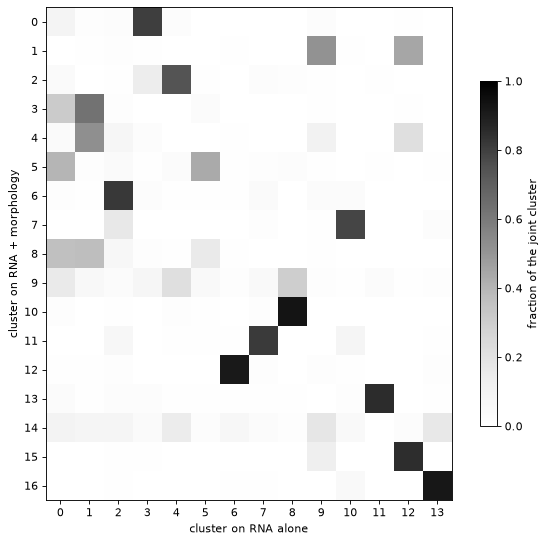

In [23]:
from sklearn.metrics import adjusted_rand_score

print(f"agreement of the two clusterings (adjusted Rand index): "
      f"{adjusted_rand_score(mdata.obs['leiden_rna'], mdata.obs['leiden_joint']):.2f}")
overlap = pd.crosstab(mdata.obs["leiden_joint"], mdata.obs["leiden_rna"], normalize="index")
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(overlap.to_numpy(), cmap="Greys", vmin=0, vmax=1)
ax.set(xticks=range(overlap.shape[1]), xticklabels=overlap.columns, yticks=range(overlap.shape[0]),
       yticklabels=overlap.index, xlabel="cluster on RNA alone", ylabel="cluster on RNA + morphology")
_ = fig.colorbar(im, ax=ax, shrink=0.7, label="fraction of the joint cluster")

The two clusterings agree on the main cell types (adjusted Rand index 0.54, where 1 means identical clusterings and 0
the agreement expected by chance). Each row of the heatmap is a joint cluster, split by the RNA clusters of its cells.
Several cell types are one cluster in both (dark squares). The joint clustering splits two RNA clusters of myeloid cells
(0 and 1) into four joint clusters (3, 4, 5 and 8). The marker plots below identify these as two macrophage states (3
and 8), CD11c+ VISTA+ myeloid cells (5) and tumor cells with macrophage signal (4). Two joint clusters (9 and 14) gather
cells from many RNA clusters. These are rare cell types that the RNA alone scatters.

To name the clusters we look at markers: the mean intensity of each stain per cluster, and the expression of marker
genes per cluster. In both plots the color is scaled per marker, from its lowest to its highest cluster. In the RNA
dotplot the size of a dot is the fraction of cells with the gene detected. Every cell has a stain intensity, so the
stains are shown as a heatmap instead.

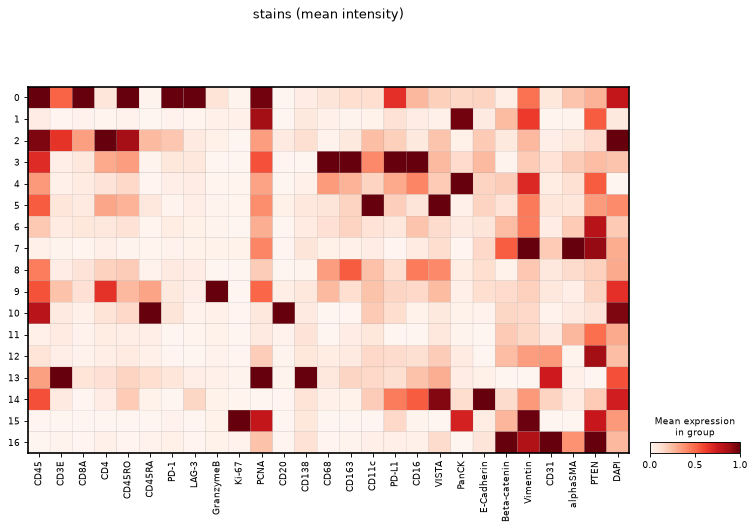

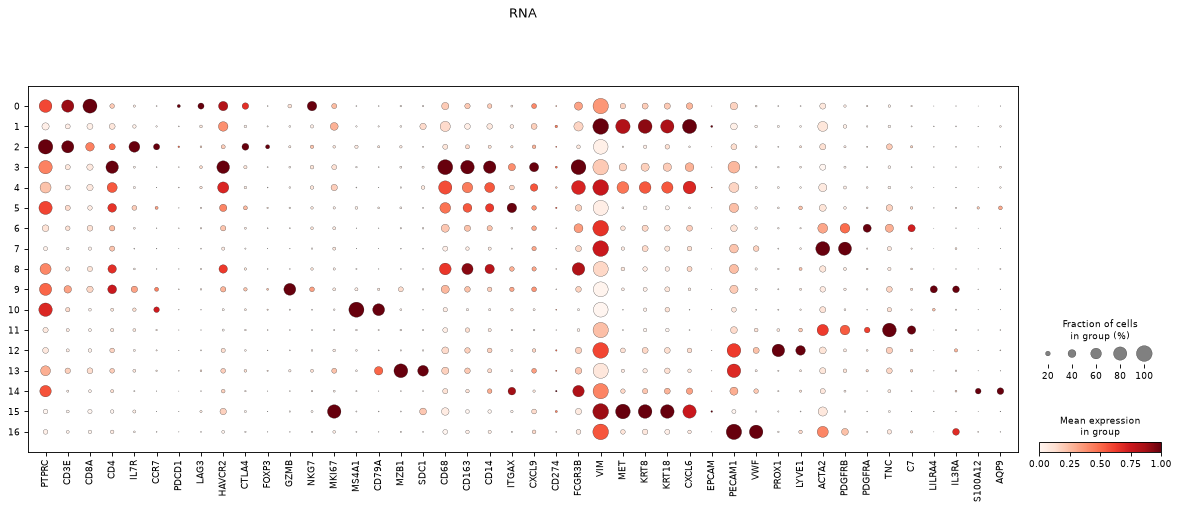

In [24]:
PROTEIN_MARKERS = ["CD45", "CD3E", "CD8A", "CD4", "CD45RO", "CD45RA", "PD-1", "LAG-3", "GranzymeB", "Ki-67", "PCNA",
                   "CD20", "CD138", "CD68", "CD163", "CD11c", "PD-L1", "CD16", "VISTA", "PanCK",
                   "E-Cadherin", "Beta-catenin", "Vimentin", "CD31", "alphaSMA", "PTEN", "DAPI"]
RNA_MARKERS = ["PTPRC", "CD3E", "CD8A", "CD4", "IL7R", "CCR7", "PDCD1", "LAG3", "HAVCR2", "CTLA4", "FOXP3", "GZMB",
               "NKG7", "MKI67", "MS4A1", "CD79A", "MZB1", "SDC1", "CD68", "CD163", "CD14", "ITGAX", "CXCL9", "CD274",
               "FCGR3B", "VIM", "MET", "KRT8", "KRT18", "CXCL6", "EPCAM", "PECAM1", "VWF", "PROX1", "LYVE1", "ACTA2",
               "PDGFRB", "PDGFRA", "TNC", "C7", "LILRA4", "IL3RA", "S100A12", "AQP9"]
RNA_MARKERS = [g for g in RNA_MARKERS if g in rna.var_names]
# the mean intensity of each stain, as an AnnData for scanpy's plots
stain_view = ad.AnnData(morph.obsm["mean_intensity"][PROTEIN_MARKERS].to_numpy(), obs=mdata.obs[["leiden_joint"]],
                        var=pd.DataFrame(index=PROTEIN_MARKERS))
rna.obs["leiden_joint"] = mdata.obs["leiden_joint"].values
sc.pl.matrixplot(stain_view, PROTEIN_MARKERS, groupby="leiden_joint", standard_scale="var", cmap="Reds",
                 title="stains (mean intensity)")
sc.pl.dotplot(rna, RNA_MARKERS, groupby="leiden_joint", standard_scale="var", title="RNA")

**Reading the plots.** Each row is a joint cluster.

- The two modalities support each other: the clusters with CD8A stain are those with *CD8A* transcripts.
- They also complement each other. The PD-1 and LAG-3 stains mark a CD8 T cell cluster whose *PDCD1* transcripts are
  almost absent, while the RNA separates the lymphatic endothelium (*PROX1*, *LYVE1*) from the blood endothelium, which
  a single CD31 stain cannot.
- The RNA names two rare immune cell types for which the panel has no defining stain: plasmacytoid dendritic cells
  (*LILRA4*, *IL3RA*; bright in the GranzymeB and CD4 stains, as expected of pDCs) and neutrophils (*S100A12*, *AQP9*).
  *FCGR3B*, normally specific to neutrophils, is detected in the macrophage clusters too, possibly because its probes
  also bind the closely related *FCGR3A*. It therefore does not define the neutrophils here.
- The stains split the macrophages into two states: one bright in CD68, CD163, PD-L1 and CD16, and one dimmer in all of
  them.
- We call the cluster bright in PD-1 and LAG-3 "PD-1+ LAG-3+ CD8 T cells", the phenotype of chronically stimulated,
  exhausted-like T cells. PD-1 and LAG-3 also rise on recently activated T cells, and the panel lacks the markers that
  would separate the two (*TOX*, *TCF7*). The CD4 and naive T cell cluster (*IL7R*, *CCR7*) also contains *FOXP3*+
  cells, so it likely includes regulatory T cells.
- The plasma cells are bright in the CD3E and CD31 stains, which they do not express. Immunoglobulin-rich plasma cells
  are a known source of non-specific antibody binding, so we do not read these two stains as protein in plasma cells.
- The panel has no classical ccRCC tumor markers (*CA9*, *PAX8*, *NDUFA4L2*). The tumor cells are recognized by *MET*,
  *CXCL6* and *KRT8* transcripts, the PanCK stain, their size and their location in the tumor. As expected for ccRCC,
  they lack E-cadherin.
- One tumor cluster also carries macrophage transcripts and stains (*CD68* and *CD163*, in both transcripts and stain),
  most likely because the outlines of its cells include part of a neighboring macrophage, a common segmentation error
  where macrophages press against tumor cells. We keep it as its own group.

We name the clusters from these markers, and group them into compartments:

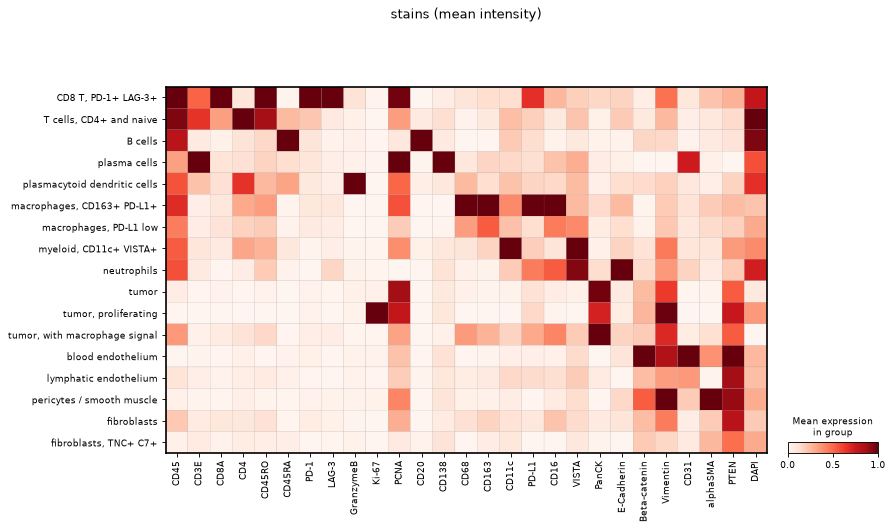

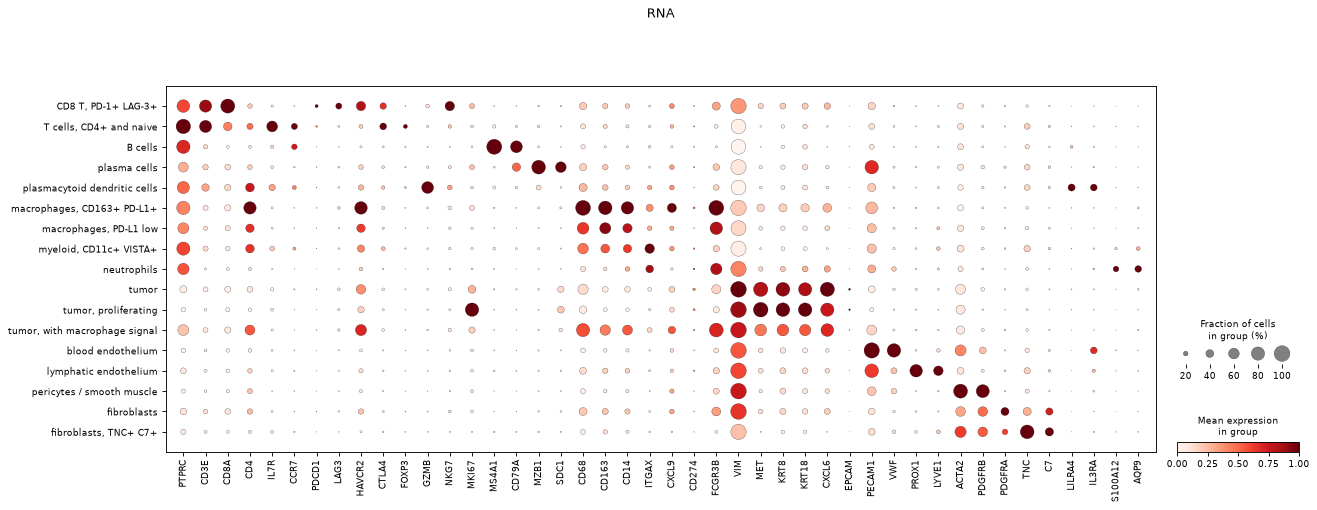

,cells,% of cells
cell_type,,
"CD8 T, PD-1+ LAG-3+",50683,12.4
"T cells, CD4+ and naive",49552,12.1
B cells,22472,5.5
plasma cells,20044,4.9
plasmacytoid dendritic cells,2260,0.6
"macrophages, CD163+ PD-L1+",32146,7.9
"macrophages, PD-L1 low",46076,11.3
"myeloid, CD11c+ VISTA+",12953,3.2
neutrophils,1572,0.4


In [25]:
CELL_TYPES = {  # joint cluster: (cell type, compartment)
    "0": ("CD8 T, PD-1+ LAG-3+", "T cells"),
    "2": ("T cells, CD4+ and naive", "T cells"),
    "10": ("B cells", "B and plasma cells"),
    "13": ("plasma cells", "B and plasma cells"),
    "9": ("plasmacytoid dendritic cells", "myeloid and dendritic"),
    "3": ("macrophages, CD163+ PD-L1+", "myeloid and dendritic"),
    "8": ("macrophages, PD-L1 low", "myeloid and dendritic"),
    "5": ("myeloid, CD11c+ VISTA+", "myeloid and dendritic"),
    "14": ("neutrophils", "myeloid and dendritic"),
    "1": ("tumor", "tumor"),
    "15": ("tumor, proliferating", "tumor"),
    "4": ("tumor, with macrophage signal", "tumor"),
    "16": ("blood endothelium", "vessels and stroma"),
    "12": ("lymphatic endothelium", "vessels and stroma"),
    "7": ("pericytes / smooth muscle", "vessels and stroma"),
    "6": ("fibroblasts", "vessels and stroma"),
    "11": ("fibroblasts, TNC+ C7+", "vessels and stroma"),
}
assert set(CELL_TYPES) == set(mdata.obs["leiden_joint"].cat.categories), "the clusters changed: revisit the annotation"
types = [t for t, _ in CELL_TYPES.values()]
mdata.obs["cell_type"] = pd.Categorical(mdata.obs["leiden_joint"].map({c: t for c, (t, _) in CELL_TYPES.items()}),
                                        categories=types)
mdata.obs["compartment"] = mdata.obs["leiden_joint"].map({c: k for c, (_, k) in CELL_TYPES.items()}).astype("category")
COLORS = dict(zip(types, sc.pl.palettes.default_20, strict=False))  # one color per cell type, in every plot
for adata in (mdata, rna, stain_view):
    adata.obs["cell_type"] = mdata.obs["cell_type"].values
    adata.uns["cell_type_colors"] = list(COLORS.values())
sc.pl.matrixplot(stain_view, PROTEIN_MARKERS, groupby="cell_type", standard_scale="var", cmap="Reds",
                 title="stains (mean intensity)")
sc.pl.dotplot(rna, RNA_MARKERS, groupby="cell_type", standard_scale="var", title="RNA")
counts = mdata.obs["cell_type"].value_counts().reindex(types)
pd.DataFrame({"cells": counts, "% of cells": (100 * counts / counts.sum()).round(1)})

### What does the morphology add to the RNA?

We look at this in three ways. The weight WNN learned for every cell, averaged per cell type, shows how much each
modality counts. The heatmap above shows which cells the joint clustering groups differently from the RNA alone. The
table below asks what in the images, beyond how bright a stain is, tells the cell types apart. For each cell type it
gives the selected non-intensity morphology feature that best separates the type from all other cells (the largest ANOVA
F statistic, on 50,000 random cells), the feature's mean z-score in the type, which gives its direction, and how closely
the feature follows the mean intensity of its stain.

,feature,mean z-score in the type,rho with the stain's mean intensity
"CD8 T, PD-1+ LAG-3+",LAG-3 texture: difference entropy,1.97028,0.891574
"T cells, CD4+ and naive",CD4 texture: sum variance,1.54378,0.859662
B cells,CD20 radial distribution: Zernike magnitude,3.098978,0.53114
plasma cells,CD138 texture: sum entropy,2.50684,0.769756
plasmacytoid dendritic cells,GranzymeB radial distribution: Zernike magnitude,7.973485,0.999981
"macrophages, CD163+ PD-L1+",CD68 radial distribution: Zernike magnitude,1.876329,0.88452
"macrophages, PD-L1 low",CD68 texture: entropy,1.070044,0.948685
"myeloid, CD11c+ VISTA+",VISTA texture: sum variance,2.071555,0.895871
neutrophils,E-Cadherin texture: sum variance,5.35563,0.840334
tumor,shape: inertia tensor eigenvalues,1.450214,NaN


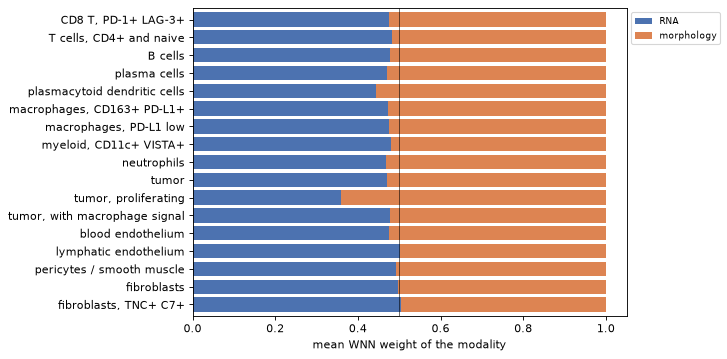

In [26]:
from sklearn.feature_selection import f_classif

wnn_weights = (mdata.obs.groupby("cell_type", observed=True)[["rna_weight", "morph_weight"]].mean()
               .set_axis(["RNA", "morphology"], axis=1))
ax = wnn_weights.plot.barh(stacked=True, figsize=(7, 5), color=["#4C72B0", "#DD8452"], width=0.8)
ax.invert_yaxis()
ax.axvline(0.5, color="k", lw=0.5)
ax.set(xlabel="mean WNN weight of the modality", ylabel="")
ax.legend(bbox_to_anchor=(1, 1), fontsize=8)

sample_cells = np.sort(np.random.default_rng(0).choice(mdata.n_obs, 50_000, replace=False))
labels = mdata.obs["cell_type"].astype(str).to_numpy()[sample_cells]
not_intensity = np.flatnonzero((morph.var["feature_group"] != "Intensity").to_numpy())
X = morph.X[sample_cells][:, not_intensity]
names = helpers.feature_labels(morph.var).to_numpy()[not_intensity]
stain_of = morph.var["channel"].to_numpy()[not_intensity]
intensity_sample = morph.obsm["mean_intensity"].iloc[sample_cells]
best = {}
for cell_type in types:
    F, _ = f_classif(X, labels == cell_type)
    i = int(np.nanargmax(F))
    stain = stain_of[i]
    best[cell_type] = {"feature": names[i], "mean z-score in the type": X[labels == cell_type, i].mean(),
                       "rho with the stain's mean intensity": (spearmanr(X[:, i], intensity_sample[stain]).statistic
                                                               if isinstance(stain, str) else np.nan)}
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(best).T.round(2))

WNN gives the two modalities about equal weight in most cell types. The exception is the proliferating tumor cells,
where the morphology counts for about two thirds, most likely because the Ki-67 stain marks them more reliably than
their sparse *MKI67* transcripts.

The non-intensity feature that best tells a cell type apart is mostly a texture or radial distribution feature of the
type's own marker stain. For a sparse stain these features rise with its brightness (last column), so the table mostly
shows which stain separates a type, and only in part how the signal is arranged in the cell. Proliferating tumor cells
are set apart by the texture of Ki-67, the plasmacytoid dendritic cells by the pattern of GranzymeB, and the neutrophils
by the texture of the E-cadherin stain. Neutrophils do not express E-cadherin, so their brightness in this stain is most
likely non-specific binding or autofluorescence. The tumor cells are set apart by their shape.

In section 3 we kept the cells that mantispy flagged for an unusual area, because in a tissue the flag marks cell types.
The share of flagged cells per cell type:

In [27]:
flagged = morph.obs["qc_area_outlier"].groupby(mdata.obs["cell_type"].to_numpy(), observed=True).mean()
(100 * flagged.reindex(types)).round(1).rename("% flagged as unusual area").to_frame().T

,"CD8 T, PD-1+ LAG-3+","T cells, CD4+ and naive",B cells,plasma cells,plasmacytoid dendritic cells,"macrophages, CD163+ PD-L1+","macrophages, PD-L1 low","myeloid, CD11c+ VISTA+",neutrophils,tumor,"tumor, proliferating","tumor, with macrophage signal",blood endothelium,lymphatic endothelium,pericytes / smooth muscle,fibroblasts,"fibroblasts, TNC+ C7+"
% flagged as unusual area,0.0,0.0,0.0,0.1,0.1,1.1,0.2,0.1,0.0,34.3,9.4,12.4,0.6,1.5,0.4,1.9,0.5


A third of the tumor cells are flagged as unusually large, against at most 2% of the non-tumor types.

### UMAPs of the RNA and the joint graph

A UMAP of 50,000 random cells, from the RNA alone and from both modalities (WNN), colored by the joint cell types. For
speed, the neighbor graphs, including the WNN weights, are recomputed on these cells only, so the UMAP approximates the
graph the clusters were computed on.

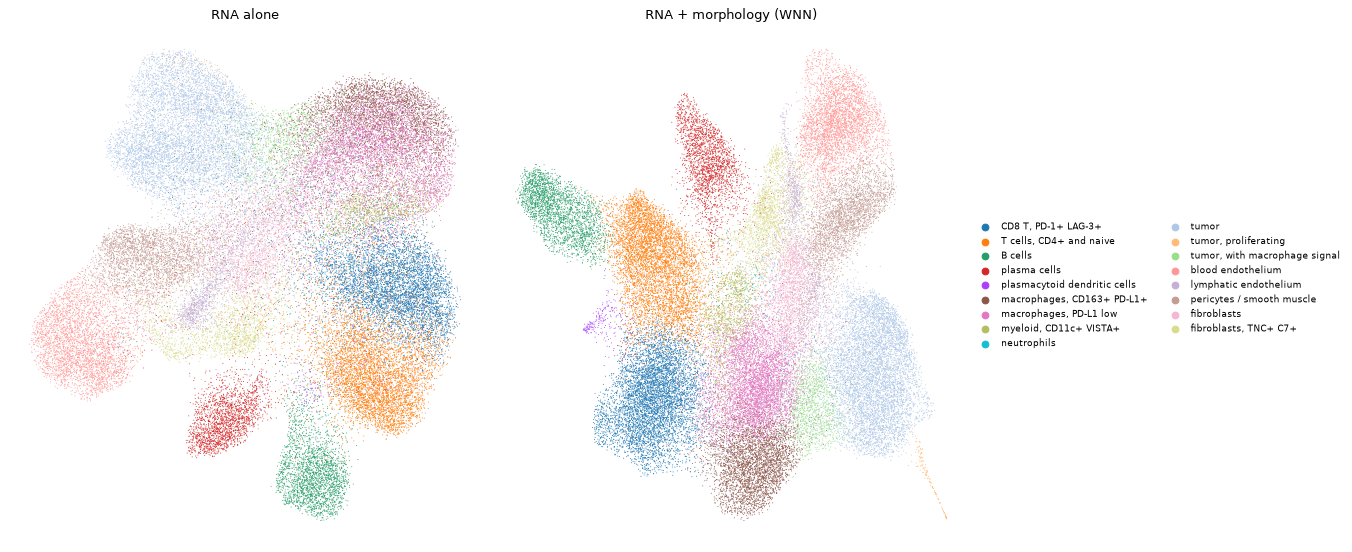

In [28]:
view = mdata[np.sort(np.random.default_rng(1).choice(mdata.n_obs, 50_000, replace=False))].copy()
sc.pp.neighbors(view.mod["rna"], use_rep="X_pca", n_neighbors=20, random_state=0)
sc.pp.neighbors(view.mod["morph"], use_rep="X_pca", n_neighbors=20, random_state=0)
mu.pp.neighbors(view, n_neighbors=20, key_added="wnn")
sc.tl.umap(view.mod["rna"], random_state=0)
mu.tl.umap(view, neighbors_key="wnn", random_state=0)
view.mod["rna"].obs["cell_type"] = view.obs["cell_type"].values
for adata in (view, view.mod["rna"]):
    adata.uns["cell_type_colors"] = list(COLORS.values())
fig, axs = plt.subplots(1, 2, figsize=(17, 7))
sc.pl.umap(view.mod["rna"], color="cell_type", ax=axs[0], show=False, title="RNA alone", legend_loc="none", size=3,
           frameon=False)
sc.pl.embedding(view, basis="X_umap", color="cell_type", ax=axs[1], show=False, title="RNA + morphology (WNN)",
                legend_loc="right margin", legend_fontsize=8, size=3, frameon=False)
plt.tight_layout()

On the RNA alone, the myeloid cell types run into each other and into the tumor cells with macrophage signal. With the
morphology they separate, and the plasmacytoid dendritic cells form an island of their own. This is partly expected,
because the cell types were defined on the joint graph. Still, the RNA alone does not place them apart.

## 6. How are the immune cells organized relative to the tumor?

*Where are the immune cells, and in which state?*

### Which cells live where?

The pathologist marked the tumor and, separately, the immune infiltrate along the upper edge. For each cell type, which
fraction of its cells sits in each region, and what is each region made of?

share of the cells of the two regions that are in the tumor: 79%


compartment,B and plasma cells,T cells,myeloid and dendritic,tumor,vessels and stroma
pathology,,,,,
Tumor,0.05,0.22,0.26,0.22,0.24
Immune infiltration,0.30,0.33,0.14,0.01,0.23


pathology,Tumor,Immune infiltration
cell_type,,
"CD8 T, PD-1+ LAG-3+",0.98,0.02
"T cells, CD4+ and naive",0.42,0.58
B cells,0.06,0.94
plasma cells,0.83,0.17
plasmacytoid dendritic cells,0.61,0.39
"macrophages, CD163+ PD-L1+",0.99,0.01
"macrophages, PD-L1 low",0.91,0.09
"myeloid, CD11c+ VISTA+",0.45,0.55
neutrophils,0.79,0.21


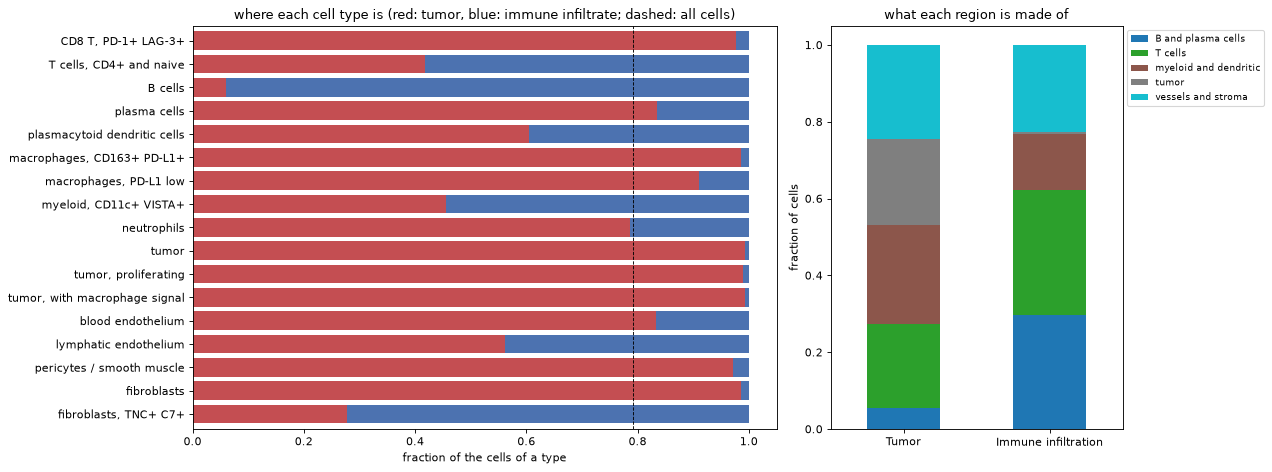

In [29]:
regions = ["Tumor", "Immune infiltration"]
in_region = mdata.obs[mdata.obs["pathology"].isin(regions)]
in_region = in_region.assign(cell_type=in_region["cell_type"].cat.remove_unused_categories(),
                             compartment=in_region["compartment"].cat.remove_unused_categories())
location = pd.crosstab(in_region["cell_type"], in_region["pathology"].astype(str), normalize="index")[regions]
composition = pd.crosstab(in_region["pathology"].astype(str), in_region["compartment"], normalize="index").loc[regions]
tumor_share = (in_region["pathology"] == "Tumor").mean()  # where a cell type without preference would lie
fig, axs = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [2, 1]})
location.plot.barh(stacked=True, ax=axs[0], color=["#C44E52", "#4C72B0"], width=0.8, legend=False)
axs[0].invert_yaxis()
axs[0].axvline(tumor_share, color="k", ls="--", lw=0.8)
axs[0].set(xlabel="fraction of the cells of a type", ylabel="",
           title="where each cell type is (red: tumor, blue: immune infiltrate; dashed: all cells)")
composition.plot.bar(stacked=True, ax=axs[1], colormap="tab10", rot=0)
axs[1].set(ylabel="fraction of cells", xlabel="", title="what each region is made of")
axs[1].legend(bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout()
print(f"share of the cells of the two regions that are in the tumor: {tumor_share:.0%}")
display(composition.round(2))
location.round(2)

The tumor holds 79% of the cells of the two regions, so a cell type without a preference for either would have 79% of
its cells in the tumor (dashed line). The PD-1+ LAG-3+ CD8 T cells and the CD163+ PD-L1+ macrophages are enriched in the
tumor (98% and 99%). The immune infiltrate holds 94% of the B cells (against 21% of all cells), 58% of the CD4 and naive
T cells, 55% of the CD11c+ VISTA+ myeloid cells and 72% of the TNC+ C7+ fibroblasts. Plasma cells, neutrophils and blood
endothelium are split between the regions in the same proportion as all cells.

By count, tumor cells are only about a fifth of the cells of the tumor region, and myeloid cells, T cells, and vessels
and stroma about a quarter each. By area the tumor cells dominate, since they are much larger. Still, immune cells
outnumber tumor cells, as expected of one of the most immune-infiltrated tumors. The infiltrate resembles lymphoid
tissue: B cells, naive T cells, its own fibroblast type (TNC+ C7+), and the B cell aggregates of the factor maps. The
tumor holds PD-1+ LAG-3+ CD8 T cells and CD163+ PD-L1+ macrophages, the cell types of a chronically stimulated T cell
response.

### Are the T cells in the tumor in a different state?

PD-1 and LAG-3 rise with chronic antigen stimulation, which leads to exhaustion. We compare their stains in the PD-1+
LAG-3+ CD8 T cells of the tumor and of the immune infiltrate, with CD45RO (memory) and Ki-67 (proliferation) for
reference.

CD8 T cells per region: {'Tumor': 48366, 'Immune infiltration': 1177}
median in the tumor / median in the immune infiltrate: {'PD-1': 1.37, 'LAG-3': 1.68, 'CD45RO': 1.04, 'Ki-67': 1.13}


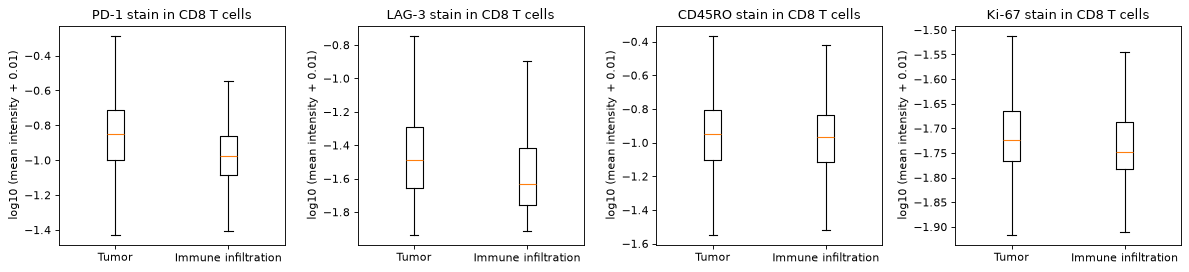

In [30]:
cd8 = in_region[in_region["cell_type"] == "CD8 T, PD-1+ LAG-3+"]
stains = morph.obsm["mean_intensity"].loc[cd8.index, ["PD-1", "LAG-3", "CD45RO", "Ki-67"]]
fig, axs = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, stain in zip(axs, stains.columns, strict=True):
    ax.boxplot([np.log10(stains.loc[cd8["pathology"] == r, stain] + 0.01) for r in regions], tick_labels=regions,
               showfliers=False)
    ax.set_title(f"{stain} stain in CD8 T cells")
    ax.set_ylabel("log10 (mean intensity + 0.01)")
plt.tight_layout()
print("CD8 T cells per region:", cd8["pathology"].value_counts()[regions].to_dict())
medians = stains.groupby(cd8["pathology"].astype(str)).median()
print("median in the tumor / median in the immune infiltrate:",
      (medians.loc["Tumor"] / medians.loc["Immune infiltration"]).astype(float).round(2).to_dict())

The PD-1+ LAG-3+ CD8 T cells are almost all in the tumor (48,366 cells, against 1,177 in the infiltrate). Within this
cluster, the cells in the tumor carry more PD-1 and LAG-3 stain than the few in the infiltrate (medians 1.4 and 1.7
times higher), although the distributions overlap broadly. CD45RO differs little (ratio 1.0), and Ki-67 is near
background in both regions, so these cells proliferate little in either. Higher PD-1 and LAG-3 fit chronic antigen
stimulation in the tumor, with three caveats. The comparison is within a cluster selected for these stains. The PD-1 low
CD8 T cells of the infiltrate were likely assigned to the CD4 and naive T cell cluster. And where cells are packed
densely, stain from neighboring cells can add to a cell's intensity.

### Who are the neighbors of the PD-1+ LAG-3+ CD8 T cells?

For each cell type in the tumor, the fraction of its neighbors that are PD-1+ LAG-3+ CD8 T cells. Neighbors are cells
whose centroids lie within 20 µm, about one to two cell diameters, so these are mostly touching cells. The red line is
the fraction of these T cells among all cells of the tumor: a bar to its right means the cell type has them as neighbors
more often than the average cell.

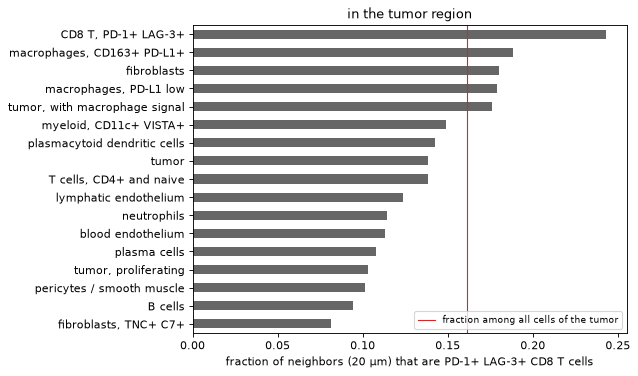

In [31]:
within_20um = NearestNeighbors(radius=20).fit(xy).radius_neighbors(xy, return_distance=False)
is_cd8 = (mdata.obs["cell_type"] == "CD8 T, PD-1+ LAG-3+").to_numpy()
cd8_share = np.array([is_cd8[n[n != i]].mean() if len(n) > 1 else np.nan for i, n in enumerate(within_20um)])
tumor_only = (mdata.obs["pathology"] == "Tumor").to_numpy()
contact = (pd.Series(cd8_share[tumor_only], index=mdata.obs["cell_type"][tumor_only].astype(str).to_numpy())
           .groupby(level=0).mean().sort_values())
ax = contact.plot.barh(figsize=(7, 5), color="0.4")
ax.axvline(is_cd8[tumor_only].mean(), color="C3", lw=1, label="fraction among all cells of the tumor")
ax.set(xlabel="fraction of neighbors (20 µm) that are PD-1+ LAG-3+ CD8 T cells", ylabel="",
       title="in the tumor region")
_ = ax.legend(fontsize=8, loc="lower right")

The PD-1+ LAG-3+ CD8 T cells cluster with each other: about a quarter of their neighbors are of the same type, against a
sixth (16%) of all cells in the tumor. CD163+ PD-L1+ macrophages and fibroblasts have slightly more of them as neighbors
than the average cell of the tumor (19% and 18%, against 16%), and tumor cells fewer (14%). These differences are modest
and untested, and come from one section. Part of the deficit around tumor cells is geometric, since a large cell has
fewer cells of any kind within 20 µm of its center. PD-1 on the T cells and its ligand PD-L1 on the macrophages are the
pair that checkpoint inhibitors block. That the cells carrying them are neighbors makes an interaction possible, but
does not show one. (squidpy's `sq.gr.nhood_enrichment` tests such neighborhoods against random placements of the cell
types.)

### Looking at the cells

A window of the tumor where PD-1+ LAG-3+ CD8 T cells and CD163+ PD-L1+ macrophages are most frequent: the H&E, the PD-1
and PD-L1 stains, and the cell types drawn on the segmentation.

window at x = 8020, y = 4420 µm: 748 cells of interest


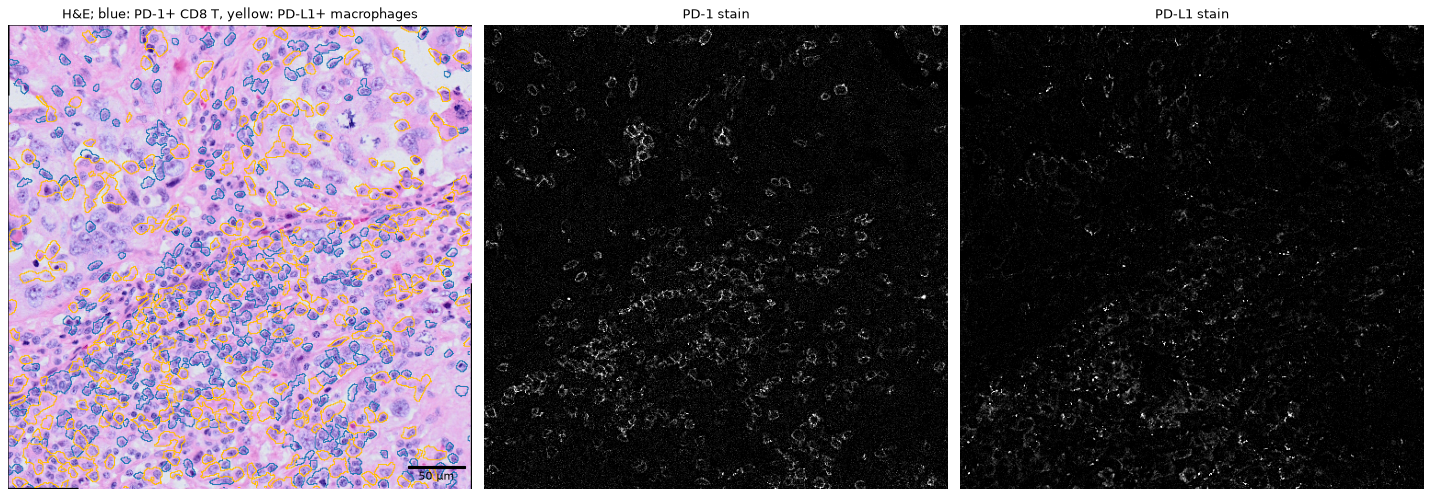

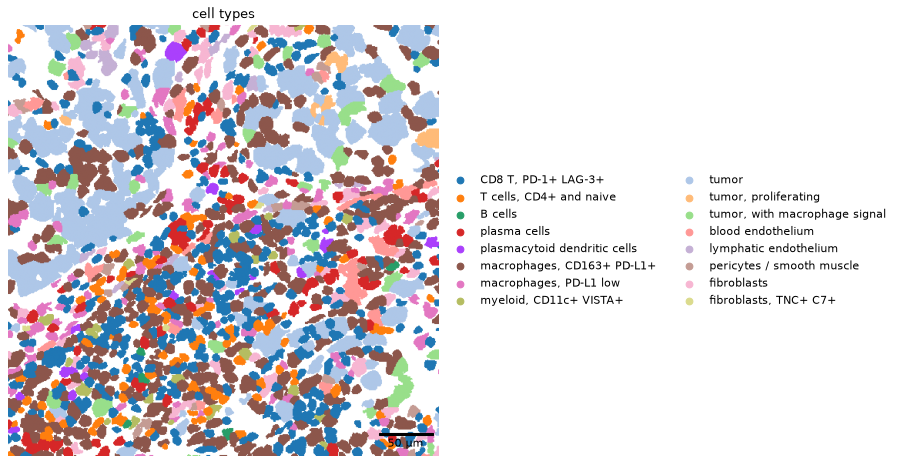

In [32]:
size = 400  # µm
interest = ["CD8 T, PD-1+ LAG-3+", "macrophages, CD163+ PD-L1+"]
of_interest = mdata.obs["cell_type"].isin(interest).to_numpy() & tumor_only
window_counts, xedges, yedges = np.histogram2d(xy[of_interest, 0], xy[of_interest, 1],
                                               bins=[np.arange(xy[:, 0].min(), xy[:, 0].max() + size, size),
                                                     np.arange(xy[:, 1].min(), xy[:, 1].max() + size, size)])
i, j = np.unravel_index(window_counts.argmax(), window_counts.shape)
lo = np.array([xedges[i], yedges[j]]) / helpers.PIXEL_SIZE
window = sdata.query.bounding_box(axes=("x", "y"), min_coordinate=lo, max_coordinate=lo + size / helpers.PIXEL_SIZE,
                                  target_coordinate_system="global")
print(f"window at x = {xedges[i]:.0f}, y = {yedges[j]:.0f} µm: {int(window_counts[i, j])} cells of interest")
fig, axs = plt.subplots(1, 3, figsize=(18, 6.3))
(window.pl.render_images("he")
 .pl.render_labels("cell_labels", color="cell_type", table_name="table", groups=interest, fill_alpha=0,
                   palette=["#1f77b4", "#ffbf00"], outline_alpha=1, contour_px=3)
 .pl.show(coordinate_systems="global", ax=axs[0], legend_loc=None,
          title="H&E; blue: PD-1+ CD8 T, yellow: PD-L1+ macrophages"))
for ax, channel in [(axs[1], "PD-1"), (axs[2], "PD-L1")]:
    pixels = window["stains"]["scale0"]["image"].sel(c=channel).data[::2, ::2].compute()
    window.pl.render_images("stains", channel=channel, cmap="gray",
                            norm=plt.Normalize(*np.percentile(pixels, [50, 99.9])), colorbar=False).pl.show(
        coordinate_systems="global", ax=ax, title=f"{channel} stain")
for ax in axs:
    ax.set_axis_off()
helpers.scale_bar(axs[0], 50, "50 µm", units_per_pixel=helpers.PIXEL_SIZE)
plt.tight_layout()

fig, ax = plt.subplots(figsize=(9, 7))
window.pl.render_labels("cell_labels", color="cell_type", table_name="table", fill_alpha=1, groups=types,
                        palette=list(COLORS.values())).pl.show(coordinate_systems="global", ax=ax, title="cell types")
helpers.scale_bar(ax, 50, "50 µm", units_per_pixel=helpers.PIXEL_SIZE)
ax.set_axis_off()

The PD-1+ LAG-3+ CD8 T cells (blue) and the CD163+ PD-L1+ macrophages (yellow) intermingle in the stroma between nests
of tumor cells, the large pale cells of the H&E. The PD-1 stain rings small round cells; the PD-L1 stain is faint and
punctate. The map of cell types shows the tumor nests bordered by macrophages and T cells.

## 7. Where does the protein add to the RNA?

*Do transcripts and protein agree, and where does the protein help?*

For 23 of the stains the gene is on the RNA panel, so we measured the same gene twice, once as transcripts and once as
protein in the images. Do the two agree, and where does the sparse RNA miss what the protein shows?

### Do transcripts and protein agree?

For each pair we compute Spearman's rho across cells, between the raw transcript counts and the mean intensity of the
stain, and across cell types, between the mean log-normalized expression of each type and its mean stain intensity.
Because rho is a rank correlation, the normalization of the RNA makes little difference.

,gene,cells with a transcript,"Spearman rho, per cell","Spearman rho, per cell type"
E-Cadherin,CDH1,0.03,-0.01,-0.00
PD-1,PDCD1,0.03,0.14,0.78
PD-L1,CD274,0.04,0.04,0.63
GranzymeB,GZMB,0.06,0.16,0.45
LAG-3,LAG3,0.08,0.21,0.68
CD20,MS4A1,0.10,0.38,0.81
CD138,SDC1,0.11,0.17,0.02
CD11c,ITGAX,0.13,0.17,0.89
Ki-67,MKI67,0.17,0.22,0.47
VISTA,VSIR,0.24,0.11,0.95


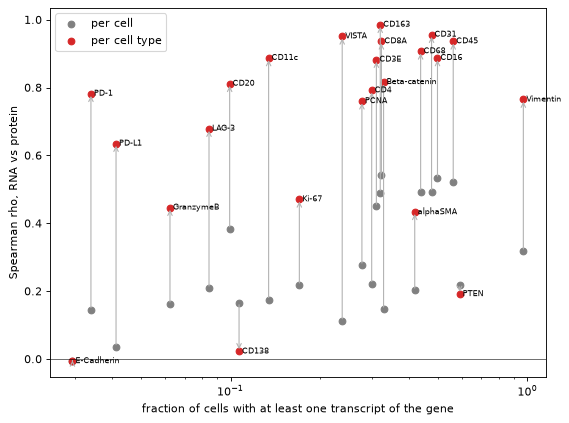

In [33]:
PAIRS = {"CD3E": "CD3E", "CD8A": "CD8A", "CD4": "CD4", "CD45": "PTPRC", "CD20": "MS4A1", "CD138": "SDC1",
         "CD68": "CD68", "CD163": "CD163", "CD11c": "ITGAX", "PD-1": "PDCD1", "LAG-3": "LAG3",
         "PD-L1": "CD274", "VISTA": "VSIR", "GranzymeB": "GZMB", "Ki-67": "MKI67", "PCNA": "PCNA", "CD31": "PECAM1",
         "Vimentin": "VIM", "alphaSMA": "ACTA2", "E-Cadherin": "CDH1", "Beta-catenin": "CTNNB1", "PTEN": "PTEN",
         "CD16": "FCGR3A"}  # stain: gene
PAIRS = {p: g for p, g in PAIRS.items() if g in rna.var_names}
rna_counts = sc.get.obs_df(rna, keys=list(PAIRS.values()), layer="counts")
intensity = morph.obsm["mean_intensity"]
cell_type = mdata.obs["cell_type"].astype(str)
type_rna = rna[:, list(PAIRS.values())].to_df().groupby(cell_type.to_numpy()).mean()  # log-normalized
type_prot = intensity.groupby(cell_type.to_numpy()).mean()
pairs = pd.DataFrame({
    "gene": list(PAIRS.values()),
    "cells with a transcript": [(rna_counts[g] > 0).mean() for g in PAIRS.values()],
    "Spearman rho, per cell": [spearmanr(rna_counts[g], intensity[p]).statistic for p, g in PAIRS.items()],
    "Spearman rho, per cell type": [spearmanr(type_rna[g], type_prot[p]).statistic for p, g in PAIRS.items()],
}, index=list(PAIRS))
fig, ax = plt.subplots(figsize=(8, 6))
for _, row in pairs.iterrows():
    ax.annotate("", xy=(row["cells with a transcript"], row["Spearman rho, per cell type"]),
                xytext=(row["cells with a transcript"], row["Spearman rho, per cell"]),
                arrowprops={"arrowstyle": "->", "color": "0.7"})
ax.scatter(pairs["cells with a transcript"], pairs["Spearman rho, per cell"], color="0.5", label="per cell")
ax.scatter(pairs["cells with a transcript"], pairs["Spearman rho, per cell type"], color="C3", label="per cell type")
for name, row in pairs.iterrows():
    ax.text(row["cells with a transcript"], row["Spearman rho, per cell type"], " " + name, fontsize=7, va="center")
ax.set(xscale="log", xlabel="fraction of cells with at least one transcript of the gene",
       ylabel="Spearman rho, RNA vs protein")
ax.axhline(0, color="k", lw=0.5)
ax.legend()
pairs.sort_values("cells with a transcript").round(2)

Per cell, transcripts and protein agree weakly: at most a Spearman rho of 0.54 (CD8A), and close to 0 for genes detected
in few cells (*CDH1*, *CD274*, *PDCD1*, each in under 5% of the cells). Averaged per cell type, most pairs agree well
(rho above 0.75 for 15 of the 23), so the disagreement per cell is mostly due to sampling, since a cell yields only a
handful of transcripts of a gene. This per-type agreement is somewhat inflated, because the 17 types were defined from
these same stains and genes. A few pairs disagree even per cell type. The E-cadherin stain peaks in neutrophils, which
do not express it, and *CDH1* is barely detected. PTEN, present in most cells, varies little between types in either
modality. CD138 and *SDC1* both peak in plasma cells, but rank the other types differently at low levels.

### Where the RNA misses a marker, is the stain there?

For each marker that defines a cell type, the table gives the fraction of the type's cells with no transcript of the
gene and, of those, the fraction whose stain is brighter than in 95% of the other cells.

In [34]:
DEFINING = {  # stain: the cell types it defines
    "CD8A": ["CD8 T, PD-1+ LAG-3+"], "CD3E": ["CD8 T, PD-1+ LAG-3+", "T cells, CD4+ and naive"],
    "CD4": ["T cells, CD4+ and naive"], "PD-1": ["CD8 T, PD-1+ LAG-3+"], "LAG-3": ["CD8 T, PD-1+ LAG-3+"],
    "CD20": ["B cells"], "CD138": ["plasma cells"], "CD68": ["macrophages, CD163+ PD-L1+", "macrophages, PD-L1 low"],
    "CD163": ["macrophages, CD163+ PD-L1+", "macrophages, PD-L1 low"], "CD31": ["blood endothelium"],
}
rows = []
for protein, targets in DEFINING.items():
    target = cell_type.isin(targets).to_numpy()
    threshold = np.percentile(intensity[protein][~target], 95)
    no_rna = (rna_counts[PAIRS[protein]] == 0).to_numpy()[target]
    high = (intensity[protein] > threshold).to_numpy()[target]
    rows.append({"stain": protein, "gene": PAIRS[protein], "cells": " + ".join(targets),
                 "no transcript": no_rna.mean(), "stain high": high.mean(),
                 "stain high among those without a transcript": high[no_rna].mean()})
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(rows).set_index("stain").round(2))

,gene,cells,no transcript,stain high,stain high among those without a transcript
stain,,,,,
CD8A,CD8A,"CD8 T, PD-1+ LAG-3+",0.14,0.82,0.73
CD3E,CD3E,"CD8 T, PD-1+ LAG-3+ + T cells, CD4+ and naive",0.29,0.52,0.47
CD4,CD4,"T cells, CD4+ and naive",0.71,0.66,0.60
PD-1,PDCD1,"CD8 T, PD-1+ LAG-3+",0.88,0.84,0.83
LAG-3,LAG3,"CD8 T, PD-1+ LAG-3+",0.72,0.84,0.80
CD20,MS4A1,B cells,0.05,1.00,0.99
CD138,SDC1,plasma cells,0.40,0.81,0.75
CD68,CD68,"macrophages, CD163+ PD-L1+ + macrophages, PD-L1 low",0.22,0.61,0.40
CD163,CD163,"macrophages, CD163+ PD-L1+ + macrophages, PD-L1 low",0.29,0.54,0.35


The RNA misses many cells of a type: 88% of the PD-1+ LAG-3+ CD8 T cells have no *PDCD1* transcript, 72% no *LAG3*, and
71% of the CD4 and naive T cells no *CD4*. Most of these cells are bright in the matching stain: of the cells without a
transcript, 83% (PD-1), 80% (LAG-3) and 60% (CD4) have a stain brighter than in 95% of the other cells. This is partly
by construction, since the stains were among the features that defined these clusters. It shows that the stain carries
the marker where the RNA missed it. It does not show that the stain alone would find these cells. The threshold also
lets through 5% of all other cells, which for a rare type can be as many cells as the type itself. For the macrophage
markers fewer cells pass (CD68 40%, CD163 35%), because their stains differ between the two macrophage states.

## 8. Saving the analysis

The annotated table with both modalities, together with the cell outlines, the segmentation and the pathology regions,
makes a light SpatialData object without the images, which stay with the original data. It can be shared and read back.

In [35]:
light = sd.SpatialData(shapes={"cell_boundaries": sdata["cell_boundaries"], "pathology": sdata["pathology"]},
                       labels={"cell_labels": sdata["cell_labels"]}, tables={"table": mdata})
out = Path("rcc_multimodal.zarr")
light.write(out, overwrite=True)
reread = sd.read_zarr(out)
table = reread["table"]
print(type(table).__name__, table.shape, {name: m.shape for name, m in table.mod.items()})
print(table.obs[["cell_type", "pathology"]].head())

MuData (408798, 3199) {'rna': (408798, 405), 'morph': (408798, 2794)}
                          cell_type pathology
aaaaaglh-1      CD8 T, PD-1+ LAG-3+     Tumor
aaaadpem-1   macrophages, PD-L1 low     Tumor
aaaafdfe-1      CD8 T, PD-1+ LAG-3+     Tumor
aaaagljm-1                    tumor     Tumor
aaaahdcb-1  T cells, CD4+ and naive     Tumor


## Summary

- **Data.** The Xenium transcripts and morphology features measured from DAPI and 26 of the 27 protein stains (HLA-DR
  left out) are kept per cell in one SpatialData object with a MuData table. Each modality is prepared on its own. The
  RNA is normalized, and the morphology, measured on stains scaled from their background, goes through mantispy's
  single-cell workflow.
- **RNA and morphology.** The two modalities find the same cell types but order the cells within a type differently.
  MOFA+ identifies factors shared by both and factors specific to the morphology.
- **Joint clustering.** Clustering on both modalities splits the macrophages by their stains, separates the
  proliferating tumor cells, and isolates two rare populations, plasmacytoid dendritic cells and neutrophils.
- **Biology.** The tumor holds nearly all the PD-1+ LAG-3+ CD8 T cells and CD163+ PD-L1+ macrophages, and the
  macrophages have slightly more of these T cells as neighbors than the average tumor cell does. The immune infiltrate
  at the tumor's edge holds B cell-rich lymphoid aggregates, naive and CD4 T cells, and TNC+ C7+ fibroblasts. These are
  untested observations on one section from one patient. They describe this tumor, and generalizing them needs more
  samples.
- **RNA and protein.** For sparse genes such as *PDCD1* and *LAG3*, most cells of the matching type that have no
  transcript are bright in the stain.

## Appendix: versions

In [36]:
import importlib.metadata

for package in ["spatialdata", "spatialdata-io", "spatialdata-plot", "mudata", "muon", "anndata", "scanpy",
                "mofapy2", "squidpy", "mantispy", "cp-measure"]:
    print(f"{package:>16}: {importlib.metadata.version(package)}")

     spatialdata: 0.8.1.dev44+g135ac4842
  spatialdata-io: 0.1.dev1195+g523292142
spatialdata-plot: 0.4.4.dev2+g8f1637bea
          mudata: 0.4.1
            muon: 0.2.0


         anndata: 0.13.4
          scanpy: 1.12.4
         mofapy2: 0.7.5
         squidpy: 0.1.dev971+g716fc01b4
        mantispy: 0.1.dev115+g3d63ca00e
      cp-measure: 0.3.0
